# Prot2GO: Enhancing Protein Function Annotation with Hierarchical Graph Neural Networks

Author: Cleverson M., PhD

## Setting the Environment

### Importing Modules

In [25]:
# Importing modules

# Core modules
import os
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import string
import re
from concurrent.futures import ThreadPoolExecutor
import requests
import warnings
import powerlaw
import random

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Bio and networks
from Bio import SeqIO
from obonet import read_obo
import networkx as nx

# Text preprocessing
import spacy
from spacy.lang.en.stop_words import STOP_WORDS

# PyTorch
import torch
import torch.nn.functional as F
from torch.nn import BatchNorm1d
from torch.utils.data import Dataset, DataLoader, TensorDataset

# PyG
from torch_geometric.utils import (
    structured_negative_sampling_feasible,
    degree,
    to_undirected,
)
from torch_geometric.data import Data, HeteroData
from torch_geometric.nn import GATConv, Linear

# Huggingface
from transformers import BertTokenizer, BertModel
from sentence_transformers import SentenceTransformer

# Sklearn
from sklearn.metrics import (
    roc_auc_score,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.feature_extraction.text import TfidfVectorizer

# Model performance logging
import wandb

# Disable warnings
warnings.filterwarnings("ignore")

# Set wandb environment variable
os.environ["WANDB_NOTEBOOK_NAME"] = "model_gat.ipynb"

# Set CUDA and PyTorch environment
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.environ["TORCH"] = torch.__version__

# Check PyTorch and CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA version: {torch.version.cuda}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {device}")

PyTorch version: 2.3.0
CUDA version: 12.1
CUDA available: True
Device: cuda


### Project Folders

In [4]:
# Create project folders and define global paths

# Define project root path
root = Path("/home/clever/datascience/projects/prot2go")

# Define data path
data_folder = root / "data"

# Create folder to save GO data
go_folder = data_folder / "go"
go_folder.mkdir(parents=True, exist_ok=True)

# Create folder to save results by species
results_folder = root / "results"
results_folder.mkdir(parents=True, exist_ok=True)

# List of species (PPI data)
species = [
    "human",
    "yeast",
    "ecoli",
    "mouse",
    "elegans",
    "droso",
    "benchmark",
]

# Base directories for storing species results
base_directories = [
    "eda",  # EDA of protein and PPI data
    "metadata",  # protein and PPI metadata
    "datasets",  # protein embeddings and PPI torch datasets
]

# Create the directory structure
for specie in species:
    for base_dir in base_directories:
        folder_path = results_folder / specie / base_dir
        folder_path.mkdir(parents=True, exist_ok=True)

# Create paths to species' folders
human_folder = results_folder / "human"
ecoli_folder = results_folder / "ecoli"
yeast_folder = results_folder / "yeast"
mouse_folder = results_folder / "mouse"
elegans_folder = results_folder / "elegans"
droso_folder = results_folder / "droso"
benchmark_folder = results_folder / "benchmark"

# Define species to analyze in the session
species_folder = human_folder
print(species_folder)

/home/clever/datascience/projects/prot2go/results/human


### Custom Functions

#### Obtain Node Sampling Probability Based on Power Law Distribution of Node Degrees

Characteristics of the Power Law distribution ($ P(x) \propto x^{-\alpha} $):

1. Scale-Invariance: Power law distributions look the same at any scale.
2. Heavy Tails: There is a non-negligible probability of very large values.
3. Few Large, Many Small: Most values are small, but a few are very large.


In [5]:
# Fit powerlaw and convert to probabilities for node sampling

def fit_powerlaw(values):
    """
    Fit a power-law distribution to the input values and return the fitted values.

    Parameters:
    values (list): A list of numerical values to fit the power-law distribution.

    Returns:
    list: A list of fitted values using the power-law distribution.
    """

    fit = powerlaw.Fit(values, discrete=True)
    alpha = fit.power_law.alpha  # exponent
    xmin = fit.power_law.xmin  # minimum value for wich the power-law holds
    fitted_values = [(x / xmin) ** (-alpha) for x in values]

    # Plot distributions
    print(f"Estimated alpha: {alpha}")
    print(f"Estimated xmin: {xmin}")

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111)

    fit.plot_pdf(color="b", linestyle="-", ax=ax)
    fit.power_law.plot_pdf(color="r", linestyle="--", ax=ax)
    plt.xlabel("Value")
    plt.ylabel("Probability Density")
    plt.legend(["Empirical Data", "Fitted Power Law"])
    plt.title("Power Law Fit to Data")
    plt.show()

    return fitted_values


def normalize_to_probabilities(values):
    """
    Normalize a list of values to probabilities that sum to 1.

    Parameters:
    values (list): A list of numerical values.

    Returns:
    list: A list of normalized probabilities.
    """
    total_sum = sum(values)
    probabilities = [val / total_sum for val in values]
    return probabilities


def convert_degrees_to_probabilities(degrees):
    """
    Convert degree values to probabilities using power-law fits.

    Parameters:
    degrees (dict): A dictionary where keys are GO term nodes and values are their degree values.

    Returns:
    dict: A dictionary where keys are GO term nodes and values are their normalized probabilities.
    """
    # Step 1: Extract degree values
    degree_values = list(degrees)

    # Step 2: Fit power-law distribution
    degree_fitted = fit_powerlaw(degree_values)

    # Step 3: Normalize fitted values to probabilities
    probabilities = normalize_to_probabilities(degree_fitted)

    # Step 4: Create the resulting dictionary
    nodes = list(range(len(degree_values)))
    prob_dict = dict(zip(nodes, probabilities))

    return prob_dict

#### Text Preprocessing and Tokenization (spacy)

In [55]:
# Text preprocessing with sPaCy

nlp = spacy.load("en_core_web_sm")  # load model before to accelerate preprocessing

# Custom punctuation removal (preserving "-" and "/" for gene names)
custom_punctuation = string.punctuation.replace("-", "").replace("/", "")

# Add/remove stop words
custom_stop_words = STOP_WORDS
custom_stop_words.update(["The", "the"])

def text_preprocessing_spacy(text=str):
    """
    Preprocesses the input text using spaCy.

    This function tokenizes the input text, removes custom punctuation,
    converts tokens to lowercase, removes stop words, and lemmatizes the tokens.

    Args:
        text (str): The input text to preprocess.

    Returns:
        str: The preprocessed and lemmatized text as a single string.
    """
    doc = nlp(text)
    tokens = []
    for token in doc:
        lemma = token.lemma_.lower()
        if lemma not in custom_stop_words and token.text not in custom_punctuation:
            tokens.append(lemma)
    return " ".join(tokens)



def process_node(item):
    """
    Extracts and preprocesses Gene Ontology (GO) Directed Acyclic Graph (DAG) node data.

    This function processes a given GO term and its attributes, extracts the definition,
    preprocesses the definition text using spaCy, and returns relevant information about the GO term.

    Args:
        item (tuple): A tuple containing the GO term (str) and its attributes (dict).

    Returns:
        dict: A dictionary containing the GO term ID, name, namespace, original definition,
              definition word count, preprocessed definition, and preprocessed word count.
    """
    go_term, attr = item
    definition = attr["def"].split('"', 2)[1]
    preprocessed_text = text_preprocessing_spacy(definition)
    return {
        "go_id": go_term,
        "name": attr["name"],
        "aspect": attr["namespace"],
        "def": definition,
        "def_word_count": len(re.findall(r"\w+", definition)),
        "preprocessed": preprocessed_text,
        "preproc_word_count": len(preprocessed_text.split()),
    }

#### PPI Data Preprocessing (DIP database)

In [7]:
# Functions to extract data from DIP datasets

def extract_uniprot_ids(field):
    """
    Extracts the UniProt ID from a given field.

    Parameters:
    field (str): A string containing UniProt IDs in the format "uniprotkb:ID".

    Returns:
    str or None: The extracted UniProt ID or None if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    for uniprot_id in split_field:
        if uniprot_id.startswith("uniprotkb"):
            return uniprot_id.split(":")[1]
    return None


def extract_methods(field):
    """
    Extracts methods enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing methods in the format "method (detail)".

    Returns:
    str: Semi-colon separated methods or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_list = [
        re.search(r"\((.*?)\)", method).group(1)
        for method in split_field
        if re.search(r"\((.*?)\)", method)
    ]
    return ";".join(fragment_list) if fragment_list else ""


def extract_taxiIDs(field):
    """
    Extracts the first numeric ID from a given field.

    Parameters:
    field (str): A string containing numeric IDs.

    Returns:
    str or None: The extracted ID or None if not found.
    """
    if pd.isna(field):
        return None
    pattern = re.compile(r"\b\d+\b")
    match = pattern.search(field)
    return match.group(0) if match else None


def extract_ppi_type(field):
    """
    Extracts unique PPI types enclosed in parentheses from a given field.

    Parameters:
    field (str): A string containing PPI types in the format "type (detail)".

    Returns:
    str: Semi-colon separated unique PPI types or an empty string if not found.
    """
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_set = {
        re.search(r"\((.*?)\)", ppi_type).group(1)
        for ppi_type in split_field
        if re.search(r"\((.*?)\)", ppi_type)
    }
    return ";".join(fragment_set) if fragment_set else ""


def extract_confidence_score(field):
    """
    Extracts the confidence score from a given field.

    Parameters:
    field (str): A string containing confidence score in the format "label:score".

    Returns:
    str or None: The extracted confidence score or None if not found.
    """
    if pd.isna(field):
        return None
    parts = field.split(":")
    return parts[1] if len(parts) > 1 else None

#### Evaluate Model Performance

In [8]:
# Evaluating model performance

# Evaluate train and validation during training
def evaluate(model, x_dict, edge_index_dict, edge_labels, val_mask, device="cuda"):
    model.to(device)
    for key in x_dict:
        x_dict[key] = x_dict[key].to(device)
    for key in edge_index_dict:
        edge_index_dict[key] = edge_index_dict[key].to(device)
    edge_labels = edge_labels.to(device)
    val_mask = val_mask.to(device)

    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, val_mask)
        val_loss = F.binary_cross_entropy_with_logits(out, edge_labels[val_mask])
        predictions = out.sigmoid()
        val_auroc = roc_auc_score(
            edge_labels[val_mask].cpu().numpy(),
            predictions.cpu().numpy(),
        )
    return val_loss.item(), val_auroc

# Evaluate model performance (test)
def predict(model, x_dict, edge_index_dict, edge_labels, mask, device="cuda"):
    model.to(device)
    for key in x_dict:
        x_dict[key] = x_dict[key].to(device)
    for key in edge_index_dict:
        edge_index_dict[key] = edge_index_dict[key].to(device)
    edge_labels = edge_labels.to(device)
    mask = mask.to(device)

    model.eval()
    with torch.no_grad():
        out = model(x_dict, edge_index_dict, mask)
        probabilities = out.sigmoid()

        true_labels = edge_labels[mask]

        auroc = roc_auc_score(true_labels.cpu().numpy(), probabilities.cpu().numpy())

        predicted_labels = (probabilities > 0.5).float()

        return predicted_labels, true_labels, auroc, probabilities


def evaluate_model_performance(
    model,
    hetero_data,
    associations_df,
    go_id_map,
    save_path,
    device="cuda" if torch.cuda.is_available() else "cpu",
):
    # Ensure Path object of save path
    save_path = Path(save_path)

    # Move model and data to device
    model.to(device)
    for key in hetero_data.x_dict:
        hetero_data.x_dict[key] = hetero_data.x_dict[key].to(device)
    for key in hetero_data.edge_index_dict:
        hetero_data.edge_index_dict[key] = hetero_data.edge_index_dict[key].to(device)
    hetero_data["protein", "associates_with", "go"].edge_label = hetero_data[
        "protein", "associates_with", "go"
    ].edge_label.to(device)
    hetero_data["protein", "associates_with", "go"].test_mask = hetero_data[
        "protein", "associates_with", "go"
    ].test_mask.to(device)

    # Extract test mask
    test_mask = hetero_data["protein", "associates_with", "go"].test_mask

    # Predict
    predicted_labels, test_labels, test_auroc, probabilities = predict(
        model,
        hetero_data.x_dict,
        hetero_data.edge_index_dict,
        hetero_data["protein", "associates_with", "go"].edge_label,
        test_mask,
        device=device,
    )

    # Retrieve the indices of the test edges
    test_edge_indices = hetero_data["protein", "associates_with", "go"].edge_index[
        :, test_mask
    ]

    # Get the protein and GO indices
    protein_indices = test_edge_indices[0].cpu().numpy()
    go_indices = test_edge_indices[1].cpu().numpy()

    # Map indices to IDs
    protein_id_map = dict(
        zip(
            associations_df["uniprot_idx"].astype(int),
            associations_df["uniprot_id"],
        )
    )
    go_id_map = {v: k for k, v in go_id_map.items()}  # swap mapping

    # Prepare data for the DataFrame
    data = {
        "Protein ID": [protein_id_map.get(idx, "Unknown") for idx in protein_indices],
        "GO ID": [go_id_map.get(idx, "Unknown") for idx in go_indices],
        "Ground Truth Label": [label.item() for label in test_labels],
        "Predicted Label": [label.item() for label in predicted_labels],
        "Probability": [prob.item() for prob in probabilities],
    }

    # Create and save df
    results_df = pd.DataFrame(data)
    results_df.to_csv(save_path / "test_results.csv", index=False)

    # Plot metrics
    print(f"AUROC test: {test_auroc:.2f}")

    # Save classification report and print
    class_report = classification_report(
        test_labels.cpu().numpy(),
        predicted_labels.cpu().numpy(),
        target_names=["0", "1"],
    )

    with open(save_path / "classification_report.txt", "w") as file:
        file.write(class_report)

    print("\nClassification Report:")
    print(class_report)

    disp = ConfusionMatrixDisplay.from_predictions(
        test_labels.cpu().numpy(),
        predicted_labels.cpu().numpy(),
        normalize="true",
        cmap="Blues",
        values_format=".1%",
    )
    plt.savefig(save_path / "confusion_matrix.png", dpi=300)
    plt.show()

    return results_df

#### Extract and Visualize Attention Weights

**Notes for improvements**:
- Averaging src and dst attention weights ensures that attention is equally split between outgoing and incoming edges.
  - *The procedure can be adjust according to specific cases, maybe checking src and dst attentions separatelly to get insights .*

In [9]:
# Extract and visualize attentions

def aggregate_attention_weights(attn_weights, edge_index, num_nodes):
    """
    Aggregate attention weights for each node based on the given edge_index.
    """
    node_attention = torch.zeros(
        (num_nodes, attn_weights.size(1)), device=attn_weights.device
    )
    assert edge_index.size(1) == attn_weights.size(
        0
    ), "Dimension mismatch between edge_index and attn_weights"

    # Use scatter_add for efficient aggregation of attention weights
    src = edge_index[0]
    dst = edge_index[1]
    node_attention.index_add_(0, src, attn_weights)
    node_attention.index_add_(0, dst, attn_weights)

    return node_attention / 2  # average


def visualize_node_importance(
    attn_weights, node_type, id_mapping, conv_layer, top_n=10
):
    """
    Visualize the importance of nodes based on aggregated attention weights using Plotly.
    """
    if attn_weights is None or not attn_weights.numel():
        print("Attention weights are empty or invalid.")
        return [], None

    attn_weights = attn_weights.mean(dim=1).cpu().detach().numpy()
    valid_weights = np.where(np.isfinite(attn_weights), attn_weights, 0)

    if not np.any(valid_weights):
        print("All attention weights are zero or invalid.")
        return [], None

    top_indices = np.argsort(valid_weights)[-top_n:][::-1]
    top_ids = [id_mapping[idx] for idx in top_indices]

    fig = go.Figure(data=[go.Bar(x=top_ids, y=valid_weights[top_indices])])

    fig.update_layout(
        title=f"Top {top_n} Important {node_type} Nodes (Conv Layer {conv_layer})",
        xaxis_title=f"Top {top_n} {node_type} Node IDs",
        yaxis_title="Importance",
        xaxis_tickangle=-45,
    )

    return top_ids, fig


def plot_node_importance(model, hetero_data, species_folder, top_n=25):
    """
    Main function to process and plot node importance for different node types using Plotly.
    """
    save_path = Path(species_folder / "models")
    (
        (edge_index_protein_1, attn_weights_protein_1),
        (edge_index_go_1, attn_weights_go_1),
        (edge_index_protein_2, attn_weights_protein_2),
        (edge_index_go_2, attn_weights_go_2),
    ) = model.get_attention_weights(hetero_data.x_dict, hetero_data.edge_index_dict)

    id_mappings = {
        "protein": {idx: id for idx, id in enumerate(hetero_data["protein"].id)},
        "go": {idx: id for idx, id in enumerate(hetero_data["go"].id)},
    }

    results = {}
    plots = []
    for node_type, attn_weights_list, edge_indices_list in [
        (
            "protein",
            [attn_weights_protein_1, attn_weights_protein_2],
            [edge_index_protein_1, edge_index_protein_2],
        ),
        (
            "go",
            [attn_weights_go_1, attn_weights_go_2],
            [edge_index_go_1, edge_index_go_2],
        ),
    ]:
        for i, (attn, edges) in enumerate(zip(attn_weights_list, edge_indices_list), 1):
            attention = aggregate_attention_weights(
                attn, edges, hetero_data[node_type].x.size(0)
            )
            top_ids, fig = visualize_node_importance(
                attention,
                node_type.capitalize(),
                id_mappings[node_type],
                conv_layer=i,
                top_n=top_n,
            )
            if fig is not None:
                fig.write_image(str(save_path / f"{node_type}_importance_{i}.png"))
                plots.append(fig)
            results[f"{node_type}_{i}"] = top_ids

    for key, ids in results.items():
        print(f"Top nodes by importance for {key}:")
        print(ids)

    return results, plots


def compare_degrees(important_nodes, node_type, edge_index, id_mapping):
    """
    Compare the degrees of the important nodes with their actual degrees.

    Parameters:
    - important_nodes: List of important node IDs.
    - node_type: Type of the node ('Protein' or 'GO Term').
    - edge_index: Edge index tensor from the graph.
    - id_mapping: Dictionary mapping node indices to their IDs.

    Returns:
    - DataFrame showing the comparison of degrees.
    """
    # Convert id_mapping to index-based mapping for quick lookup
    index_mapping = {v: k for k, v in id_mapping.items()}

    # Get the indices of the important nodes
    important_indices = [index_mapping[node_id] for node_id in important_nodes]

    # Calculate the degrees for all nodes
    row, col = edge_index
    node_degrees = degree(row, row.max().item() + 1).cpu().numpy()

    # Get the degrees of the important nodes
    important_degrees = [node_degrees[idx] for idx in important_indices]

    # Create a DataFrame for comparison
    comparison_df = pd.DataFrame(
        {"Node ID": important_nodes, "Degree": important_degrees}
    )

    # Plot the comparison
    plt.figure(figsize=(12, 6))
    plt.bar(comparison_df["Node ID"], comparison_df["Degree"])
    plt.xlabel(f"{node_type} Node IDs")
    plt.ylabel("Degree")
    plt.title(f"Degree Comparison of Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.show()

    return comparison_df

#### Analyze GO Terms

In [10]:
def analyze_go_terms(
    df, top_go_ids, information_accretion_col="ia", text_col="preprocessed", top_n=25
):
    """
    Filters GO terms based on importance, visualizes distributions of 'ia', and computes TF-IDF of definitions.

    Parameters:
    - df (pd.DataFrame): DataFrame containing GO terms with columns for 'ia' and preprocessed definitions.
    - top_go_ids (list): List of top GO IDs considered important.
    - column_name (str): Column name for the importance attribute (default 'ia').
    - preprocessed_col (str): Column name for preprocessed text data.
    - top_n (int): Number of top terms to visualize with TF-IDF.

    Returns:
    - Tuple[pd.DataFrame, list]: DataFrame filtered to top GO terms and list of key top tokens that differ.
    """
    # Filter DataFrame to get top GO terms
    top_go_df = df[df["go_id"].isin(top_go_ids)]

    # Plotting distributions
    plt.figure(figsize=(12, 6))
    plt.hist(df[information_accretion_col], bins=30, alpha=0.5, label="All GO Terms")
    plt.scatter(
        top_go_df[information_accretion_col],
        np.zeros_like(top_go_df[information_accretion_col]),
        color="red",
        label="Top GO Terms",
    )
    plt.title("Distribution of 'ia' across all GO terms and top GO terms")
    plt.xlabel("ia")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

    # Function to compute and plot TF-IDF
    def plot_tfidf(texts, label):
        vectorizer = TfidfVectorizer(max_df=0.85, min_df=2, ngram_range=(1, 2))
        tf_idf_matrix = vectorizer.fit_transform(texts)
        max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()
        sorted_indices = np.argsort(max_scores)[::-1][:top_n]
        sorted_features = vectorizer.get_feature_names_out()[sorted_indices]
        sorted_scores = max_scores[sorted_indices]

        plt.figure(figsize=(12, 8))
        bars = plt.barh(sorted_features, sorted_scores, color="green")
        plt.xlabel("Max TF-IDF Score")
        plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores in {label}")
        plt.gca().invert_yaxis()
        plt.show()

        return sorted_features

    # Compute and plot TF-IDF for all GO terms and top GO terms
    all_tokens = plot_tfidf(df[text_col], "All GO Terms")
    top_tokens = plot_tfidf(top_go_df[text_col], "Top GO Terms")

    # Identify key top tokens that are different between the two sets
    key_top_tokens = list(set(top_tokens) - set(all_tokens))

    return top_go_df, key_top_tokens

In [11]:
# Plot training metrics

# Plot loss and accuracy (training results)
def plot_loss_and_accuracy(metrics, save_path):
    epochs = list(metrics["train_losses"].keys())

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, list(metrics["train_losses"].values()), label="Training Loss")
    plt.plot(epochs, list(metrics["val_losses"].values()), label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, list(metrics["train_aurocs"].values()), label="Training AUROC")
    plt.plot(epochs, list(metrics["val_aurocs"].values()), label="Validation AUROC")
    plt.xlabel("Epoch")
    plt.ylabel("AUROC")
    plt.title("Training and Validation AUROC")
    plt.legend()

    plt.tight_layout()
    plt.savefig(save_path / "training_metrics.png", dpi=300)
    plt.show()

### Custom Classes

#### ProteinDataset Class

In [12]:
class ProteinDataset(Dataset):
    """
    A PyTorch Dataset class for reading and preprocessing protein sequences for embedding generation.

    Attributes:
        dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").

    Methods:
        __len__: Returns the number of files in the dataset.
        __getitem__: Retrieves a sequence and its identifier by index, applying preprocessing.
    """

    def __init__(self, dataframe):
        """
        Initializes the ProteinDataset with a dataframe.

        Parameters:
            dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").
        """
        self.dataframe = dataframe

    def __len__(self):
        """
        Provides the size of the dataset.

        Returns:
            int: The number of sequences in the dataframe.
        """
        return len(self.dataframe)

    def __getitem__(self, idx):
        """
        Retrieves the sequence and its identifier at the specified index after preprocessing.

        Parameters:
            idx (int): The index of the sequence to retrieve.

        Returns:
            tuple: A tuple containing the preprocessed sequence and its id.
        """
        row = self.dataframe.iloc[idx]
        seq = " ".join(row["sequence"].replace(r"[UZOB]", "X"))

        return seq, row["uniprot_id"]

#### ProteinEmbedding Dataset Class

In [13]:
class ProteinEmbeddingDataset(Dataset):
    """
    A PyTorch Dataset for loading protein embeddings stored as .pt (PyTorch tensor) files.

    Each tensor file contains the embedding of a protein, identified by a UniProt ID. This dataset
    facilitates the access to these embeddings for model training or inference, ensuring each
    embedding is loaded as needed, thus optimizing memory usage.

    Attributes:
        tensor_folder (str): The directory path where the embedding tensors (.pt files) are stored.
        uniprot_ids (list): A list of UniProt IDs corresponding to the proteins for which embeddings are available.

    Methods:
        __len__: Returns the total number of embeddings available in the dataset.
        __getitem__: Retrieves an embedding by its index, along with its corresponding UniProt ID.

    Parameters:
        tensor_folder (str): Path to the folder where tensor files, representing protein embeddings, are stored.
                             Each file should be named with the UniProt ID of the protein it represents.
    """

    def __init__(self, tensor_folder):
        """
        Initializes the dataset with the path to the directory containing the embeddings.

        Args:
            tensor_folder (string): Path to the folder where tensors are stored.
        """
        self.tensor_folder = tensor_folder
        self.uniprot_ids = [
            file.split(".")[0]
            for file in os.listdir(tensor_folder)
            if file.endswith(".pt")
        ]

    def __len__(self):
        """
        Returns the total number of protein embeddings available.

        Returns:
            int: The count of UniProt ID-based tensor files in the tensor folder.
        """
        return len(self.uniprot_ids)

    def __getitem__(self, idx):
        """
        Retrieves a specific protein embedding and its corresponding UniProt ID by index.

        This method ensures that the embedding tensor is loaded from disk only when accessed,
        optimizing memory usage, especially useful when dealing with large datasets.

        Args:
            idx (int): The index of the protein embedding to retrieve.

        Returns:
            dict: A dictionary containing the UniProt ID ('uniprot_id') and the embedding tensor ('tensor').
                  The tensor is expected to have a shape of (1, 1024).

        Raises:
            AssertionError: If the loaded tensor does not match the expected shape of (1, 1024).
        """
        uniprot_id = self.uniprot_ids[idx]
        tensor_path = os.path.join(self.tensor_folder, uniprot_id + ".pt")
        tensor = torch.load(tensor_path)

        # Asserting the tensor is in the correct shape ensures consistency and prevents potential errors in downstream processes.
        assert tensor.shape == (
            1,
            1024,
        ), f"Tensor shape mismatch: {tensor.shape} != (1, 1024)"

        return {"uniprot_id": uniprot_id, "tensor": tensor}

#### Protein Sequence Embedding

In [14]:
def embed_sequences(
    dataframe: pd.DataFrame, out_dir: Path, per_residue=False, batch_size=1
):
    """
    Processes protein sequences from a folder, generating embeddings using a pre-trained BERT model.

    Parameters:
        dataframe (pd.DataFrame): A dataframe with protein IDs, corresponding peptide sequences and their lengths.
        per_residue (bool): If True, saves per-residue embeddings; otherwise, saves per-protein embeddings.
        batch_size (int): The batch size for processing sequences.
    """

    print(f"Loading transformer and tokenizer...")
    tokenizer = BertTokenizer.from_pretrained("Rostlab/prot_bert", do_lower_case=False)
    model = BertModel.from_pretrained("Rostlab/prot_bert")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).half().eval()  # move model to gpu and set half-precision (float16)

    # Creates directories to save embeddings
    out_dir = Path(out_dir)  # ensures Path object
    out_dir.mkdir(parents=True, exist_ok=True)

    per_protein_path = out_dir / "per_protein"
    per_protein_path.mkdir(exist_ok=True, parents=True)

    per_residue_path = out_dir / "per_residue" if per_residue else None
    if per_residue_path:
        per_residue_path.mkdir(exist_ok=True, parents=True)

    # Reads fasta files in input folder
    dataset = ProteinDataset(dataframe)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for seqs, ids in tqdm(loader, desc="Embedding sequences"):
        for seq, seq_id in zip(seqs, ids):

            # Tokenize and move input tensors to the same device as the model
            inputs = tokenizer(seq, padding=True, truncation=True, return_tensors="pt")
            inputs = {key: tensor.to(device) for key, tensor in inputs.items()}

            with torch.no_grad():
                outputs = model(**inputs)
            protein_embeddings = outputs.last_hidden_state[
                :, : len(seq.replace(" ", "")) + 1
            ]

            # Detach and move to CPU before saving
            protein_embeddings = protein_embeddings.mean(dim=1).detach().cpu()
            torch.save(protein_embeddings, per_protein_path / f"{seq_id}.pt")

            if per_residue:
                residue_embeddings = outputs.last_hidden_state[
                    :, : len(seq.replace(" ", "")) + 1
                ]
                torch.save(
                    residue_embeddings.detach().cpu(),
                    per_residue_path / f"{seq_id}_res_embed.pt",
                )

    print(f"All proteins embedded successfully.")

#### Text Embedding with Sentence Transformer

In [15]:
class TextDataset(Dataset):
    def __init__(self, dataframe, text_column):
        self.texts = dataframe[text_column].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def embed_texts(df, column_id, column_text):
    """
    Generates embeddings for text data in a DataFrame using a Sentence Transformer model.

    Parameters:
    - df (pandas.DataFrame): The DataFrame containing the text data.
    - column_id (str): The name of the column in the DataFrame that contains the identifiers for the text.
    - column_text (str): The name of the column in the DataFrame that contains the text to be embedded.

    Returns:
    - dict: A dictionary where the keys are entries from `column_id` and the values are the embeddings
            generated from the text in `column_text`.
    """
    # Load Sentence Transformer
    model = SentenceTransformer(
        "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cuda:0"
    )

    # Create dataset from DataFrame
    dataset = TextDataset(df, column_text)
    dataloader = DataLoader(dataset, batch_size=128, shuffle=False)

    embeddings_dict = dict()
    for texts in tqdm(dataloader, total=len(dataloader)):
        embeddings = model.encode(
            texts, show_progress_bar=False, convert_to_tensor=True
        )
        for text, emb in zip(texts, embeddings):
            go_id = df[df[column_text] == text][column_id].values[0]
            embeddings_dict[go_id] = emb.cpu().numpy()

    print("All texts embedded successfully.")
    return embeddings_dict

#### Protein-GO Dataloader Class

In [16]:
class ProteinGoDataloader:
    def __init__(self, protein_ids_map, go_ids_map, species_folder):
        self.protein_ids_map = protein_ids_map
        self.go_ids_map = go_ids_map
        self.species_folder = Path(species_folder)
        self.edge_index_protgo_positive = None
        self.edge_index_protgo_negative = None
        self.associations_negative_df = None
        self.hetero_data = None
        self.train_mask = None
        self.val_mask = None
        self.test_mask = None
        self.train_protein_ids = None
        self.val_protein_ids = None
        self.test_protein_ids = None
        self.train_go_ids = None
        self.val_go_ids = None
        self.test_go_ids = None

    def generate_negative_edges(
        self,
        edge_index,
        num_nodes_protein,
        num_nodes_go,
        num_neg_samples,
        weighted=False,
        random_state=42,
        max_attempts_factor=10,
    ):
        rng = np.random.default_rng(random_state)
        existing_edges = set(map(tuple, edge_index.t().tolist()))

        if weighted:
            protein_degrees = np.zeros(num_nodes_protein, dtype=int)
            for protein_node, go_node in edge_index.t().tolist():
                protein_degrees[protein_node] += 1

        negative_samples = []
        attempts = 0
        max_attempts = num_neg_samples * max_attempts_factor
        neg_degree_count = np.zeros(num_nodes_protein, dtype=int) if weighted else None

        while len(negative_samples) < num_neg_samples and attempts < max_attempts:
            if weighted:
                protein_node = rng.choice(
                    num_nodes_protein, p=protein_degrees / protein_degrees.sum()
                )
            else:
                protein_node = rng.integers(0, num_nodes_protein)

            go_node = rng.integers(0, num_nodes_go)

            if (protein_node, go_node) not in existing_edges:
                negative_samples.append([protein_node, go_node])
                if weighted:
                    neg_degree_count[protein_node] += 1

            attempts += 1

        neg_sample_tensor = (
            torch.tensor(negative_samples, dtype=torch.long).t()
            if negative_samples
            else torch.empty((2, 0), dtype=torch.long)
        )

        protein_mapping = {v: k for k, v in self.protein_ids_map.items()}
        go_mapping = {v: k for k, v in self.go_ids_map.items()}

        mapped_negative_samples = [
            {
                "uniprot_id": protein_mapping.get(u_idx, None),
                "go_id": go_mapping.get(g_idx, None),
                "uniprot_idx": u_idx,
                "go_idx": g_idx,
            }
            for u_idx, g_idx in negative_samples
        ]

        self.associations_negative_df = pd.DataFrame(mapped_negative_samples)
        self.edge_index_protgo_negative = neg_sample_tensor

    def check_balance(
        self, positive_edge_index, negative_edge_index, num_nodes_protein, num_nodes_go
    ):
        protein_degrees_pos = np.zeros(num_nodes_protein, dtype=int)
        go_degrees_pos = np.zeros(num_nodes_go, dtype=int)
        for protein_node, go_node in positive_edge_index.t().tolist():
            protein_degrees_pos[protein_node] += 1
            go_degrees_pos[go_node] += 1

        protein_degrees_neg = np.zeros(num_nodes_protein, dtype=int)
        go_degrees_neg = np.zeros(num_nodes_go, dtype=int)
        for protein_node, go_node in negative_edge_index.t().tolist():
            protein_degrees_neg[protein_node] += 1
            go_degrees_neg[go_node] += 1

        plt.figure(figsize=(12, 6))
        plt.subplot(1, 2, 1)
        sns.kdeplot(
            protein_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
        )
        sns.kdeplot(
            protein_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5
        )
        plt.title("Protein Degree Distribution")
        plt.xlabel("Degree")
        plt.ylabel("Density")
        plt.legend()

        plt.subplot(1, 2, 2)
        sns.kdeplot(
            go_degrees_pos, color="blue", label="Positive", fill=True, alpha=0.5
        )
        sns.kdeplot(go_degrees_neg, color="red", label="Negative", fill=True, alpha=0.5)
        plt.title("GO Terms Degree Distribution")
        plt.xlabel("Degree")
        plt.ylabel("Density")
        plt.legend()

        plt.tight_layout()
        plt.savefig(self.species_folder / "balance_check.png", dpi=300)
        plt.show()

    def create_heterodata(
        self,
        protein_feats,
        go_feats,
        protein_ids,
        go_ids,
        edge_index_ppi,
        edge_index_go,
        edge_index_protgo_positive,
    ):
        
        # Make PPI graph undirected
        edge_index_ppi = to_undirected(edge_index_ppi)
        
        edge_index_protgo = torch.cat(
            (edge_index_protgo_positive, self.edge_index_protgo_negative), dim=1
        )
        positive_labels = torch.ones(
            edge_index_protgo_positive.shape[1], dtype=torch.float32
        )
        negative_labels = torch.zeros(
            self.edge_index_protgo_negative.shape[1], dtype=torch.float32
        )
        edge_labels = torch.cat((positive_labels, negative_labels), dim=0)

        hetero_data = HeteroData()
        hetero_data["protein"].x = protein_feats
        hetero_data["go"].x = go_feats
        hetero_data["protein"].id = protein_ids
        hetero_data["go"].id = go_ids
        hetero_data["protein", "ppi", "protein"].edge_index = edge_index_ppi
        hetero_data["go", "relation", "go"].edge_index = edge_index_go
        hetero_data["protein", "associates_with", "go"].edge_index = edge_index_protgo
        hetero_data["protein", "associates_with", "go"].edge_label = edge_labels

        self.hetero_data = hetero_data

    def split_dataset(self, train_ratio=0.6):
        val_ratio = (1 - train_ratio) / 2
        test_ratio = val_ratio
        assert isinstance(train_ratio, float), "Train ratio must be a float."
        assert 0 < train_ratio < 1, "Train ratio must be between 0 and 1."

        unique_proteins, edge_positions = torch.unique(
            self.hetero_data["protein", "associates_with", "go"].edge_index[0],
            return_inverse=True,
        )
        permuted_indices = torch.randperm(unique_proteins.size(0))
        num_proteins = unique_proteins.size(0)
        train_end = int(num_proteins * train_ratio)
        val_end = int(num_proteins * (train_ratio + val_ratio))

        train_proteins = permuted_indices[:train_end]
        val_proteins = permuted_indices[train_end:val_end]
        test_proteins = permuted_indices[val_end:]

        train_mask = edge_positions.unsqueeze(0).eq(train_proteins.unsqueeze(1)).any(0)
        val_mask = edge_positions.unsqueeze(0).eq(val_proteins.unsqueeze(1)).any(0)
        test_mask = edge_positions.unsqueeze(0).eq(test_proteins.unsqueeze(1)).any(0)

        self.hetero_data["protein", "associates_with", "go"]["train_mask"] = train_mask
        self.hetero_data["protein", "associates_with", "go"]["val_mask"] = val_mask
        self.hetero_data["protein", "associates_with", "go"]["test_mask"] = test_mask

        self.train_mask = train_mask
        self.val_mask = val_mask
        self.test_mask = test_mask

        protein_mapping = {v: k for k, v in self.protein_ids_map.items()}
        go_mapping = {v: k for k, v in self.go_ids_map.items()}

        self.train_protein_ids = [protein_mapping[idx.item()] for idx in train_proteins]

        self.train_protein_ids = [protein_mapping[idx.item()] for idx in train_proteins]
        self.val_protein_ids = [protein_mapping[idx.item()] for idx in val_proteins]
        self.test_protein_ids = [protein_mapping[idx.item()] for idx in test_proteins]

        train_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, train_mask]
            .tolist()
        )
        val_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, val_mask]
            .tolist()
        )
        test_go_indices = (
            self.hetero_data["protein", "associates_with", "go"]
            .edge_index[1, test_mask]
            .tolist()
        )

        self.train_go_ids = [go_mapping[idx] for idx in train_go_indices]
        self.val_go_ids = [go_mapping[idx] for idx in val_go_indices]
        self.test_go_ids = [go_mapping[idx] for idx in test_go_indices]

    def to_device(self, device):
        self.hetero_data = self.hetero_data.to(device)
        self.train_mask = self.train_mask.to(device)
        self.val_mask = self.val_mask.to(device)
        self.test_mask = self.test_mask.to(device)

    def create_data_loaders(self, batch_size=32):
        train_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.train_mask]
        train_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.train_mask]
        val_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.val_mask]
        val_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.val_mask]
        test_edge_index = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_index[:, self.test_mask]
        test_edge_label = self.hetero_data[
            "protein", "associates_with", "go"
        ].edge_label[self.test_mask]

        train_dataset = TensorDataset(train_edge_index.t(), train_edge_label)
        val_dataset = TensorDataset(val_edge_index.t(), val_edge_label)
        test_dataset = TensorDataset(test_edge_index.t(), test_edge_label)

        self.train_loader = DataLoader(
            train_dataset, batch_size=batch_size, shuffle=True
        )
        self.val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        self.test_loader = DataLoader(
            test_dataset, batch_size=batch_size, shuffle=False
        )

    def plot_label_ratios(self):
        edge_index = self.hetero_data["protein", "associates_with", "go"].edge_index
        edge_labels = self.hetero_data["protein", "associates_with", "go"].edge_label

        train_edges = edge_index[:, self.train_mask]
        train_labels = edge_labels[self.train_mask]
        val_edges = edge_index[:, self.val_mask]
        val_labels = edge_labels[self.val_mask]
        test_edges = edge_index[:, self.test_mask]
        test_labels = edge_labels[self.test_mask]

        train_label_ratio = torch.sum(train_labels) / train_labels.size(0)
        val_label_ratio = torch.sum(val_labels) / val_labels.size(0)
        test_label_ratio = torch.sum(test_labels) / test_labels.size(0)

        plt.figure(figsize=(4, 2))
        plt.bar(
            ["Train", "Val", "Test"],
            [train_label_ratio, val_label_ratio, test_label_ratio],
        )
        plt.ylabel("Label Ratio")
        plt.title("Label Ratios in Train, Validation, and Test Sets")
        plt.savefig(self.species_folder / "label_ratios.png", dpi=300)
        plt.show()

    def save_heterodata(self):
        save_file_path = self.species_folder / "datasets" / "heterodata.pt"
        torch.save(self.hetero_data, save_file_path)

    def process(
        self,
        edge_index_protgo_positive,
        protein_feats,
        go_feats,
        protein_ids,
        go_ids,
        edge_index_ppi,
        edge_index_go,
        train_ratio=0.6,
        ratio=1,
    ):
        number_pos_edges = edge_index_protgo_positive.shape[1]
        if self.structured_negative_sampling_feasible(edge_index_protgo_positive):
            print(
                f"Negative edges generation is feasible.\nGenerating {number_pos_edges * ratio} negative edges..."
            )

            self.generate_negative_edges(
                edge_index=edge_index_protgo_positive,
                num_nodes_protein=len(protein_ids),
                num_nodes_go=len(go_ids),
                num_neg_samples=number_pos_edges * ratio,
                weighted=True,
                random_state=42,
            )

            print(
                f"Protein negative associates with GO edge index shape: {self.edge_index_protgo_negative.shape}"
            )
            self.check_balance(
                edge_index_protgo_positive,
                self.edge_index_protgo_negative,
                len(protein_ids),
                len(go_ids),
            )

            self.create_heterodata(
                protein_feats,
                go_feats,
                protein_ids,
                go_ids,
                edge_index_ppi,
                edge_index_go,
                edge_index_protgo_positive,
            )

            self.split_dataset(train_ratio)
            self.plot_label_ratios()
            self.save_heterodata()

            train_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.train_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.train_mask
            ].size(
                0
            )
            val_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.val_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.val_mask
            ].size(
                0
            )
            test_label_ratio = torch.sum(
                self.hetero_data["protein", "associates_with", "go"].edge_label[
                    self.test_mask
                ]
            ) / self.hetero_data["protein", "associates_with", "go"].edge_label[
                self.test_mask
            ].size(
                0
            )

            print(
                f"Labels (ratio): train ({train_label_ratio:.2f}), val ({val_label_ratio:.2f}), test ({test_label_ratio:.2f})"
            )
            print(self.hetero_data)
        else:
            print("Negative edges generation isn't feasible.")

    def structured_negative_sampling_feasible(self, edge_index_protgo_positive):
        return structured_negative_sampling_feasible(edge_index_protgo_positive)

## Prepare GO Graph

### Download and Parse Up-to-Date Gene Ontology (GO) Graph

In [121]:
address = "https://purl.obolibrary.org/obo/go/go-basic.obo"
filepath = go_folder / "go-basic.obo"
response = requests.get(address)
response.raise_for_status()  # Check for download errors

with open(filepath, "wb") as f:
    f.write(response.content)

# Load GO Directed Acyclic Graph (GO-DAG)
go_graph = read_obo(go_folder / "go-basic.obo")

print(go_graph)
print(f"Format version: {go_graph.graph['format-version']}")
print(f"Data version: {go_graph.graph['data-version'][-10:]}")
print(f"Is Directed Acyclic Graph?: {nx.is_directed_acyclic_graph(go_graph)}")
print(f"Is strongly connected?: {nx.is_strongly_connected(go_graph)}")

MultiDiGraph named 'go' with 42203 nodes and 81344 edges
Format version: 1.2
Data version: 2024-06-10
Is Directed Acyclic Graph?: False
Is strongly connected?: False


### Extract and Tokenize GO Terms' Definitions

In [56]:
# Parallel processing of GO graph nodes

with ThreadPoolExecutor(
    max_workers=16
) as executor:  # Increase max_workers if you have more CPU cores
    results = list(
        tqdm(
            executor.map(process_node, go_graph.nodes.items()),
            total=len(go_graph.nodes),
            desc="Processing GO graph nodes...",
        )
    )

# Create DataFrame from results
go_df = pd.DataFrame(results)

# Assert if all nodes are in df and save
assert len(go_df) == len(go_graph.nodes), "Mismatch in the number of nodes."
go_df.to_csv(go_folder / "go-basic-tokenized.csv", index=False)

print(f"DataFrame dimensions: {go_df.shape}")
print(go_df.head().to_markdown())

Processing GO graph nodes...:   0%|          | 0/42203 [00:00<?, ?it/s]

DataFrame dimensions: (42203, 7)
|    | go_id      | name                                                     | aspect             | def                                                                                                                                                                                                                                                                                           |   def_word_count | preprocessed                                                                                                                                                                       |   preproc_word_count |
|---:|:-----------|:---------------------------------------------------------|:-------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [119]:
# Add Degrees and Information Accretion to GO data

# Load information accretion data
ia_df = pd.read_csv(data_folder / "cafa/information_accretion.txt", sep="\t")

# Extract unique GO terms
unique_go_ia = ia_df["go_id"].unique()

# Assign 1 to missing IA values (keeps prob of sampling node unchanged)
go_df_ia = go_df.merge(ia_df, on="go_id", how="left")

# Drop rows without IA
go_df_ia.dropna(inplace=True)
go_df_ia.reset_index(drop=True, inplace=True)

# # Remove dropped entries from go_graph (mapping edges later)
go_df = pd.read_csv(go_folder / "go-basic-tokenized.csv")
nodes_to_remove = list(set(go_df["go_id"].tolist()) - set(go_df_ia["go_id"].tolist()))
go_graph.remove_nodes_from(nodes_to_remove)

# Add degrees
degree_dict = dict(go_graph.degree)
go_df_ia["degree"] = go_df_ia["go_id"].map(degree_dict)

# Analyze IA values
ia_values = go_df_ia["ia"].values
ia_mean = ia_values.mean()
ia_sd = ia_values.std()

# Print results using logging
print(f"IA df shape: {ia_df.shape}")
print(f"Number of unique GO terms: {unique_go_ia.shape[0]}")
print(f"Mean IA values: {ia_mean:.2f}, standard deviation: {ia_sd:.2f}")

# Save df with ia and degree
go_df_ia.to_csv(go_folder / "go-basic-tokenized-ia.csv", index=False)

print(f"GO IA df shape: {go_df_ia.shape}")
print(f"Number of GO graph nodes: {go_graph.number_of_nodes()}")

go_df_ia.head()

IA df shape: (43248, 2)
Number of unique GO terms: 43248
Mean IA values: 2.81, standard deviation: 3.35
GO IA df shape: (41774, 9)
Number of GO graph nodes: 41774


,go_id,name,aspect,def,def_word_count,preprocessed,preproc_word_count,ia,degree
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,distribution mitochondria include mitochondria...,13,0.000000,2
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,maintenance structure integrity mitochondrial ...,10,3.103836,2
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,enable transfer zinc ion zn2 membrane probably...,22,4.409391,1
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,enable transfer solute solute membrane accord ...,25,5.409391,1
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,catalysis transfer mannose residue oligosaccha...,8,2.945960,3


### Generate Embeddings

In [80]:
# Generate embeddings from preprocessed texts

# load go df
go_df = pd.read_csv(go_folder / "go-basic-tokenized-ia.csv")

# generate embeddings
go_embed_dict = embed_texts(go_df, "go_id", "preprocessed")

# Save GO embeddings dict
save_file_path = go_folder / "go_embeddings_dict.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(go_embed_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"# of embeddings: {len(go_embed_dict)}")

  0%|          | 0/327 [00:00<?, ?it/s]

All texts embedded successfully.
# of embeddings: 41713


In [81]:
# Generate embeddings from raw texts

# load go df
go_df = pd.read_csv(go_folder / "go-basic-tokenized-ia.csv")

# generate embeddings
go_embed_dict = embed_texts(go_df, "go_id", "def")

# Save GO embeddings dict
save_file_path = go_folder / "go_embeddings_dict_raw.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(go_embed_dict, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"# of embeddings: {len(go_embed_dict)}")

  0%|          | 0/327 [00:00<?, ?it/s]

All texts embedded successfully.
# of embeddings: 41774


### Load Embeddings

In [82]:
# Load tokenized dataset and GO embeddings dict

go_df = pd.read_csv(go_folder / "go-basic-tokenized-ia.csv")
print(f"GO df shape: {go_df.shape}")
display(go_df.head())

save_file_path = go_folder / "go_embeddings_dict.pkl"  # preprocessed def embeddings
# save_file_path = go_folder / "go_embeddings_dict_raw.pkl"  # raw def embeddings

with open(save_file_path, "rb") as file:
    go_embed_dict = pickle.load(file)

print(f"GO embeddings dict length: {len(go_embed_dict)}")
for key, value in go_embed_dict.items():
    print(f"GO id: {key}, embedding: {value[:10]}")
    break

GO df shape: (41774, 9)


,go_id,name,aspect,def,def_word_count,preprocessed,preproc_word_count,ia,degree
0,GO:0000001,mitochondrion inheritance,biological_process,"The distribution of mitochondria, including th...",23,distribution mitochondria include mitochondria...,13,0.000000,2
1,GO:0000002,mitochondrial genome maintenance,biological_process,The maintenance of the structure and integrity...,19,maintenance structure integrity mitochondrial ...,10,3.103836,2
2,GO:0000006,high-affinity zinc transmembrane transporter a...,molecular_function,Enables the transfer of zinc ions (Zn2+) from ...,44,enable transfer zinc ion zn2 membrane probably...,22,4.409391,1
3,GO:0000007,low-affinity zinc ion transmembrane transporte...,molecular_function,Enables the transfer of a solute or solutes fr...,50,enable transfer solute solute membrane accord ...,25,5.409391,1
4,GO:0000009,"alpha-1,6-mannosyltransferase activity",molecular_function,Catalysis of the transfer of a mannose residue...,17,catalysis transfer mannose residue oligosaccha...,8,2.945960,3


GO embeddings dict length: 41713
GO id: GO:0000001, embedding: [ 0.02925766  0.1674188   0.00151008  0.01983833  0.6085832   0.03349322
 -0.04056235  0.14064568  0.09817246 -0.04038695]


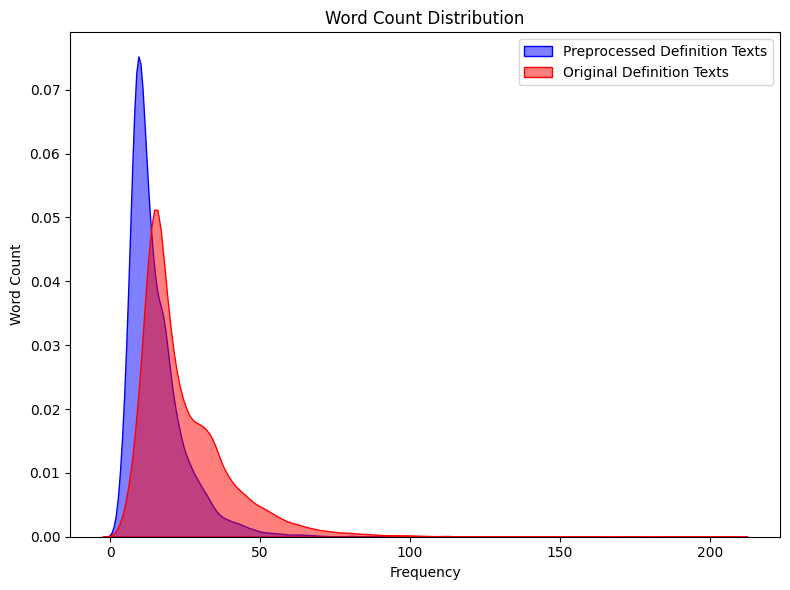

count    41774.000000
mean        15.382894
std          9.815031
min          2.000000
25%          9.000000
50%         13.000000
75%         19.000000
max        131.000000
Name: preproc_word_count, dtype: float64


In [83]:
# Plot word count distributions

plt.figure(figsize=(8, 6))
sns.kdeplot(
    go_df["preproc_word_count"],
    color="blue",
    label="Preprocessed Definition Texts",
    fill=True,
    alpha=0.5,
)
sns.kdeplot(
    go_df["def_word_count"],
    color="red",
    label="Original Definition Texts",
    fill=True,
    alpha=0.5,
)
plt.title("Word Count Distribution")
plt.xlabel("Frequency")
plt.ylabel("Word Count")
plt.legend()

plt.tight_layout()
plt.savefig(go_folder / "word_counts.png", dpi=300)
plt.show()

# Get descriptive statistics for the word counts
print(go_df["preproc_word_count"].describe())

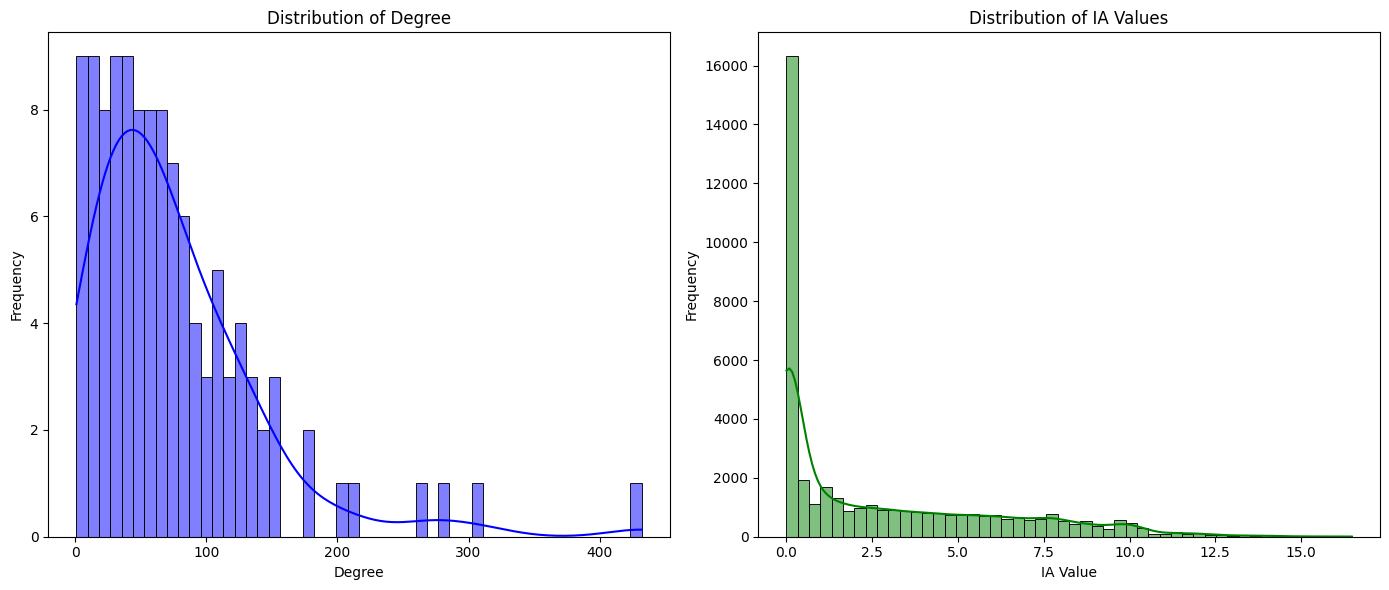

In [84]:
# Histograms for Degree and IA

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(go_df["degree"].unique(), bins=50, kde=True, ax=ax[0], color="blue")
ax[0].set_title("Distribution of Degree")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Frequency")

sns.histplot(go_df["ia"], bins=50, kde=True, ax=ax[1], color="green")
ax[1].set_title("Distribution of IA Values")
ax[1].set_xlabel("IA Value")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(go_folder / "degrees_ia_distribution.png", dpi=300)
plt.show()

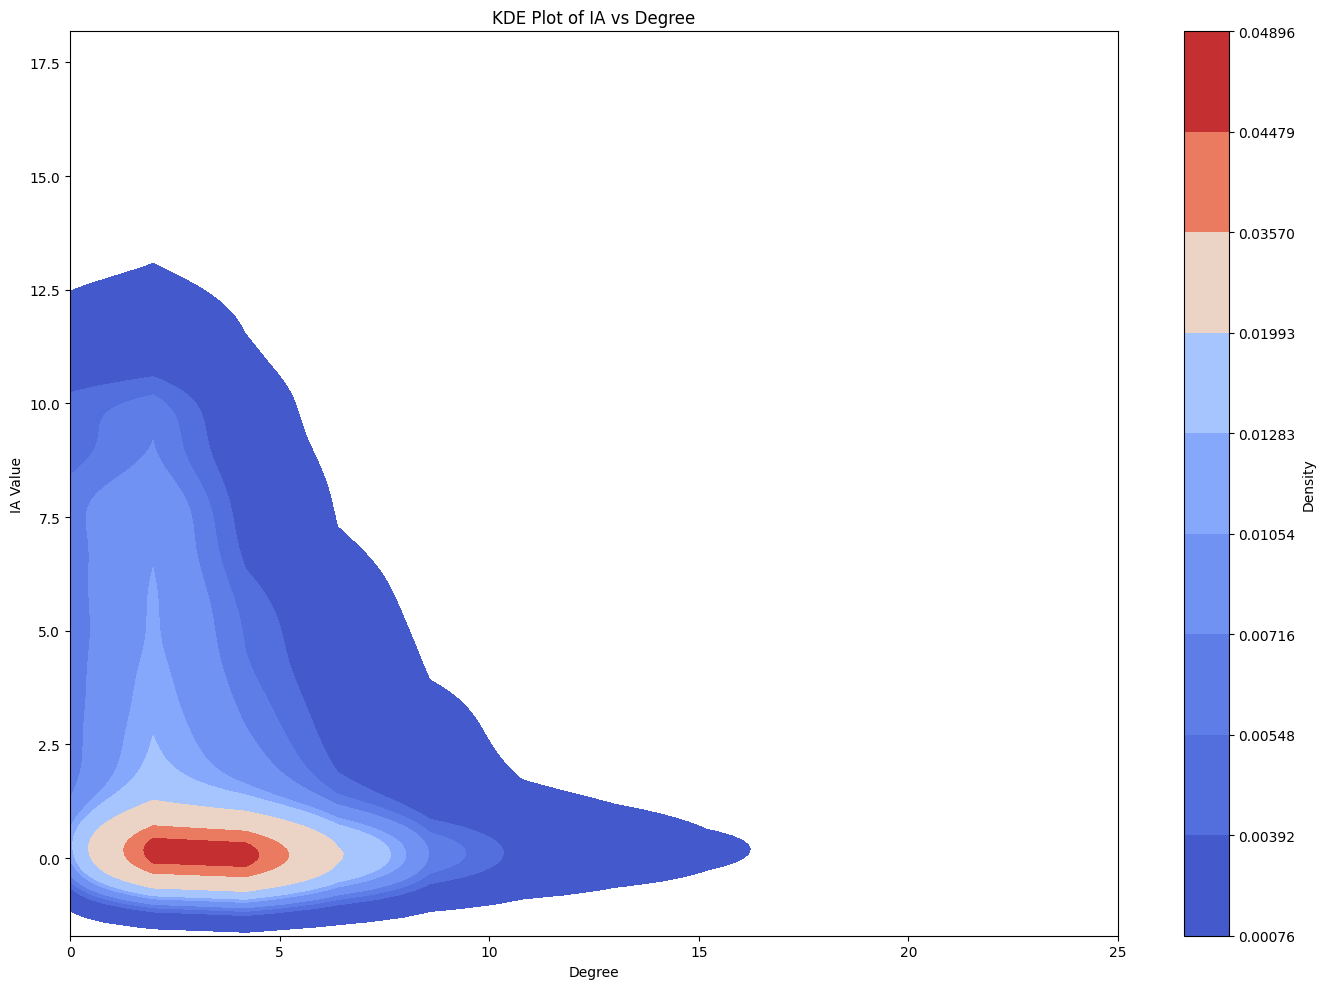

In [85]:
# KDE plot for IA vs Degree

plt.figure(figsize=(14, 10))

sns.kdeplot(
    data=go_df,
    x="degree",
    y="ia",
    cmap="coolwarm",
    fill=True,
    cbar=True,
    cbar_kws={"label": "Density"},
)
plt.xlim(0, 25)
plt.title("KDE Plot of IA vs Degree")
plt.xlabel("Degree")
plt.ylabel("IA Value")
plt.tight_layout()
plt.savefig(go_folder / "degree_vs_ia_heatmap.png", dpi=300)
plt.show()

### Build GO Graph

In [104]:
# Convert features to tensors

go_feats = torch.stack([torch.tensor(v, dtype=torch.float32) for v in go_embed_dict.values()])

# Create mapping dict
go_ids = list(go_embed_dict.keys())
go_ids_map = dict(zip(go_ids, range(len(go_ids))))
go_feats_map = dict(zip(go_ids, go_feats))

# Create dict mappings of ia and degrees
ia_values = go_df.set_index("go_id")["ia"]
go_ia_map = dict(zip(go_ids, ia_values))

degree_values = go_df.set_index("go_id")["degree"]
go_term_degree_map = dict(zip(go_ids, degree_values))

# Function to convert degrees to probabilities (dummy example)
def convert_degrees_to_probabilities(degrees):
    return degrees / degrees.sum()

# Create GO node sampling probabilities (powerlaw)
go_probs = convert_degrees_to_probabilities(degree_values)
go_probs_map = dict(zip(go_ids, go_probs))

# Assert dict length (number of nodes)
assert len(go_embed_dict) == len(go_ids), "Length mismatch."
assert len(go_feats) == len(go_ids), "Length mismatch."
assert len(go_term_degree_map) == len(go_ids), "Length mismatch."
assert len(go_ia_map) == len(go_ids), "Length mismatch."
assert len(go_probs_map) == len(go_ids), "Length mismatch."

print("All assertions passed.")


All assertions passed.


#### Define Single Edge Type

In [120]:
# Create GO graph edge_index (intra-edges)

edges_to_tensor = [
    [go_ids_map[e[0]], go_ids_map[e[1]]] for e in go_graph.edges(data=True)
]
edge_index_go = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_go.shape}")
edge_index_go

KeyError: 'GO:0072350'

In [ ]:
# Creates torch geometric HeteroData object and save GO graph

go_data = Data()
go_data.x = go_feats
go_data.ia = ia_values
go_data.degree = degree_values
go_data.edge_index = edge_index_go

# Save data
save_file_path = go_folder / "go_graph_dataset.pt"
torch.save(go_data, save_file_path)
go_data

## Prepare PPI Graph

### Filter Protein-GO Associations

In [ ]:
# Load protein-GO associations to filter obsolete GO terms

associations_df = pd.read_csv(data_folder / "cafa/associations.tsv", sep="\t")

# Filter out obsolete GO terms using up to date GO DAG
associations_df = associations_df[associations_df["go_id"].isin(go_ids)]

print(f"Protein-GO associations dims: {associations_df.shape}")
associations_df.head()

### Load (filtered) Sequences and Parse

In [ ]:
# Load and parse sequences from CAFA5

min_length = 50  # Minimum length threshold
max_length = 4000  # Maximum length threshold

# Load sequences and build df
file_path = data_folder / "cafa/train_sequences.fasta"
sequences = []
for record in SeqIO.parse(file_path, "fasta"):
    sequences.append(
        {
            "uniprot_id": record.id,
            "sequence": str(record.seq),
            "length": len(record.seq),
        }
    )

# Convert list of dictionaries to DataFrame
sequences_df = pd.DataFrame(sequences)
sequences_df = sequences_df.sort_values(by="length", ascending=False).reset_index(
    drop=True
)

# Filter sequences based on length
sequences_df_filtered = sequences_df[
    (sequences_df["length"] <= max_length) & (sequences_df["length"] >= min_length)
]

# Filter out proteins with obsolete GO terms (assuming go_nodes is defined)
valid_uniprot_ids = associations_df["uniprot_id"].to_numpy()  # extract ids of selected lenght range

filtered_sequences_df = sequences_df_filtered[
    sequences_df_filtered["uniprot_id"].isin(valid_uniprot_ids)
].reset_index(drop=True)

# Plot histogram of protein sizes
plt.figure(figsize=(4, 3))
sns.histplot(sequences_df_filtered, x="length", binwidth=10).set(
    title="Protein Size Distribution (a.a. counts)"
)
plt.savefig(data_folder / "cafa/cafa_protein_size_dist.png", dpi=300)
plt.show()

# Save the filtered data
sequences_df_filtered.to_csv(data_folder / "cafa/sequences.csv", index=False)

print(f"Sequences df dims: {sequences_df_filtered.shape}")
print(sequences_df_filtered.head())

### Load PPI Data (DIP)

In [ ]:
# Load PPI data (DIP human) and preprocess

file_path = data_folder / f"dip/{species_folder.as_posix().split("/")[-1]}.txt"  # human PPI

ppi_df = pd.read_csv(file_path, delimiter=",", on_bad_lines="warn")

print(ppi_df.info())
ppi_df.head()

In [ ]:
# Preprocess dataset

# Keep only relevant columns
ppi_df.drop(
    columns=[
        "Alt. ID interactor A",
        "Alt. ID interactor B",
        "Alias(es) interactor A",
        "Alias(es) interactor B",
        "Publication 1st author(s)",
        "Publication Identifier(s)",
        "Source database(s)",
        "Interaction identifier(s)",
        "Processing Status",
    ],
    inplace=True,
)


# Rename remaining columns
new_column_names = {
    "ID interactor A": "uniprot_id_A",
    "ID interactor B": "uniprot_id_B",
    "Interaction detection method(s)": "detection_method",
    "Taxid interactor A": "taxiID_A",
    "Taxid interactor B": "taxiID_B",
    "Interaction type(s)": "ppi_type",
    "Confidence value(s)": "confidence",
}

ppi_df.rename(columns=new_column_names, inplace=True)

# Reorder columns
ppi_df = ppi_df[
    [
        "uniprot_id_A",
        "uniprot_id_B",
        "ppi_type",
        "detection_method",
        "confidence",
        "taxiID_A",
        "taxiID_B",\
    ]
]

# Format data

# Extract uniprot ids
ppi_df["uniprot_id_A"] = ppi_df["uniprot_id_A"].apply(extract_uniprot_ids)
ppi_df["uniprot_id_B"] = ppi_df["uniprot_id_B"].apply(extract_uniprot_ids)

# Extract methods
ppi_df["detection_method"] = ppi_df["detection_method"].apply(extract_methods)

# Extract taxIDs
ppi_df["taxiID_A"] = ppi_df["taxiID_A"].apply(extract_taxiIDs)
ppi_df["taxiID_B"] = ppi_df["taxiID_B"].apply(extract_taxiIDs)

# Extract PPI type
ppi_df["ppi_type"] = ppi_df["ppi_type"].apply(extract_ppi_type)

# Extract confidence score
ppi_df["confidence"] = ppi_df["confidence"].apply(extract_confidence_score)

# Remove PPI pairs of diferent organisms
ppi_df = ppi_df[ppi_df["taxiID_A"] == ppi_df["taxiID_B"]]
ppi_df.reset_index(drop=True, inplace=True)

# Filter out PPI pairs without associations (protein-GO)
unique_associations_protein_ids = associations_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_associations_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_associations_protein_ids))
]

# Remove self-loops (A = B)
ppi_df = ppi_df[(ppi_df["uniprot_id_A"] != ppi_df["uniprot_id_B"])]

# Remove proteins without embeddings (large proteins)
unique_sequences_protein_ids = sequences_df["uniprot_id"].unique()
ppi_df = ppi_df[
    (ppi_df["uniprot_id_A"].isin(unique_sequences_protein_ids))
    & (ppi_df["uniprot_id_B"].isin(unique_sequences_protein_ids))
]

# Handling NA values in uniprot IDs
# There are entries without reference to Uniprot IDs
print(
    "# of missing UniProt IDs (A, B):",
    (
        len(ppi_df[ppi_df["uniprot_id_A"].isna()]),
        len(ppi_df[ppi_df["uniprot_id_B"].isna()]),
    ),
)

# Drop NAs
ppi_df.dropna(inplace=True)

# Reset index and save processed df
ppi_df.reset_index(drop=True, inplace=True)
ppi_df.to_csv(species_folder / "datasets/ppi.csv", index=False)

print(f"PPI df shape: {ppi_df.shape}")
print(ppi_df.head().to_markdown())
ppi_df.describe()

### Extract Metadata

In [ ]:
# Obtain PPI metadata

# Check PPI types in the dataset
# Get unique lists of ppi types
ppi_types = ppi_df["ppi_type"].unique()

# Get unique PPI types from lists of PPI types
unique_ppi_types = set(
    ppi_type.strip() for sublist in ppi_types for ppi_type in sublist.split(";")
)
unique_ppi_types = sorted(unique_ppi_types)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_types.txt"
with open(file_path, "w") as f:
    f.write(str(unique_ppi_types))

# Check PPI detection methods in the dataset
# Get unique lists of detection methods
methods = ppi_df["detection_method"].unique()

# Get unique PPI types from lists of PPI types
unique_methods = set(
    method.strip() for sublist in methods for method in sublist.split(";")
)
unique_methods = sorted(unique_methods)  # convert to list

# Save list
file_path = species_folder / "metadata/ppi_methods.txt"
with open(file_path, "w") as f:
    f.write(str(unique_methods))

print(f"# of unique PPI detection methods: {len(unique_methods)}")
print(unique_methods[:5])
print(f"# of unique PPI types: {len(unique_ppi_types)}")
print(unique_ppi_types)

In [ ]:
# PPI counts (unique)

# Extract interactions
ppi_pairs = list(
    tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
)

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)

# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of PPIs: {len(ppi_pairs)}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

### Build NetworkX Graph to Extract LCC

In [ ]:
# Construct nx graph to extract LCC

# Create undirected graph instance
ppi_graph = nx.Graph()

# Add edges
ppi_graph.add_edges_from(ppi_unique_pairs)

# Get connected components and lcc
cc = list(nx.connected_components(ppi_graph))
lcc = max(cc, key=len)

# Extract subgraph with lcc
ppi_graph_lcc = ppi_graph.subgraph(lcc).copy()

# Extract nodes and edges for graph dataset
ppi_nodes = ppi_graph_lcc.nodes()
ppi_edges = list(ppi_graph_lcc.edges())

# print-out basic graph attributes
print(f"# of nodes: {ppi_graph.number_of_nodes()}")
print(f"# of edges: {ppi_graph.number_of_edges()}")
print(f"Is connected?: {nx.is_connected(ppi_graph_lcc)}")
print(f"\n# of connected components: {len(cc)}")
print(f"\n# of nodes (LCC): {len(ppi_nodes)}")
print(f"# of edges (LCC): {len(ppi_edges)}")
print(f"Is connected? (LCC): {nx.is_connected(ppi_graph_lcc)}")

In [ ]:
# PPI counts

# Extract unique interactions
ppi_unique_pairs = list(
    set(tuple(sorted(x)) for x in ppi_df[["uniprot_id_A", "uniprot_id_B"]].to_numpy())
)
# Extract unique uniprot ids in interactions
ppi_unique_ids = pd.concat([ppi_df["uniprot_id_A"], ppi_df["uniprot_id_B"]]).unique()

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

In [ ]:
# Filter protein-go associations with LCC nodes

# Keep full protein-GO associations for plotting
associations_full = associations_df.copy()

# Remove associations with large proteins
associations_df = associations_df[
    associations_df["uniprot_id"].isin(list(ppi_graph_lcc.nodes()))
].copy()

associations_df = associations_df[
    associations_df["uniprot_id"].isin(sequences_df_filtered["uniprot_id"].unique())
]
associations_df.reset_index(drop=True, inplace=True)

# Save filtered df
file_path = species_folder / "datasets/associations.tsv"
associations_df.to_csv(file_path, sep="\t", index=False)


print(f"Filtered Protein-GO associations dims: {associations_df.shape}")
print(f"# of unique UniProt IDs: {len(associations_df['uniprot_id'].unique())}")
associations_df.head()

### Build PPI Graph

In [ ]:
# Load embeddings

emb_dataset = ProteinEmbeddingDataset(data_folder / "cafa/protein_embeddings")

print(f"# of protein embeddings: {len(emb_dataset)}")

In [ ]:
# Collect uniprot ids and embeddings from Dataloader

# iterates over dataset in batches to extract sequences and ids
protein_embed_dict = {}
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

loader = DataLoader(emb_dataset, batch_size=1, shuffle=False)
for batch in tqdm(loader, total=len(loader), desc="Loading Protein Dataset..."):
    uniprot_id = str(batch["uniprot_id"][0])
    if batch["uniprot_id"][0] in unique_proteins_lcc_cafa:
        protein_embed_dict[batch["uniprot_id"][0]] = batch["tensor"].numpy().flatten()

# Save protein embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "wb") as file:
    pickle.dump(protein_embed_dict, file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

In [ ]:
# Load protein embeddings dict

# Get unique protein ids
unique_proteins_lcc_cafa = associations_df["uniprot_id"].unique()

# Load embeddings dict
save_file_path = species_folder / "datasets/protein_embeddings.pkl"
with open(save_file_path, "rb") as file:
    protein_embed_dict = pickle.load(file)

# Convert embeddings to tensors
protein_feats = torch.stack(
    [torch.tensor(v, dtype=torch.float32) for v in protein_embed_dict.values()]
)

# Create mapping dict
protein_ids = list(protein_embed_dict.keys())
protein_ids_map = dict(zip(protein_ids, range(len(ppi_nodes))))
protein_feats_map = dict(zip(protein_ids, protein_feats))

print(f"# of protein ids: {len(protein_ids)}")
print(f"protein feats shape: {protein_feats.shape}")

for key, value in protein_ids_map.items():
    print(f"key: {key}, value: {value}")
    break

for key, value in protein_feats_map.items():
    print(f"key: {key}, value: {value.shape}")
    break

In [ ]:
# Creates edge_index

# Extracts PPI pairs for edge construction

# Ensures that every pair of nodes intersect PPI / CAFA5
edges_to_tensor = [
    [protein_ids_map[e[0]], protein_ids_map[e[1]]]
    for e in ppi_edges
    if e[0] in unique_proteins_lcc_cafa and e[1] in unique_proteins_lcc_cafa
]

edge_index_ppi = torch.tensor(edges_to_tensor, dtype=torch.long).t().contiguous()

print(f"edge_index shape: {edge_index_ppi.shape}")
edge_index_ppi

In [ ]:
# Convert PPI graph to undirected

# Convert to undirected (A-B = B-A for PPI)
# Obtain degrees from ppi graph
src_degrees = degree(edge_index_ppi[0])
dst_degrees = degree(edge_index_ppi[1])

# Convert to undirected (A-B = B-A for PPI)
edge_index_ppi = to_undirected(edge_index_ppi)
degrees = degree(edge_index_ppi[0])

# Plot degree histogram
fig, ax = plt.subplots(1, 3, figsize=(21, 6))

sns.histplot(src_degrees, bins=50, kde=True, ax=ax[0], color="red")
ax[0].set_title("Distribution of In-Degrees")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Frequency")

sns.histplot(dst_degrees, bins=50, kde=True, ax=ax[1], color="green")
ax[1].set_title("Distribution of Out-Degrees")
ax[1].set_xlabel("IA Value")
ax[1].set_ylabel("Frequency")

sns.histplot(degrees, bins=50, kde=True, ax=ax[2], color="blue")
ax[2].set_title("Distribution of Degrees")
ax[2].set_xlabel("IA Value")
ax[2].set_ylabel("Frequency")


plt.tight_layout()
plt.show()

In [ ]:
# Creates torch geometric Data object and save

ppi_data = Data()
ppi_data.x = protein_feats
ppi_data.edge_index = edge_index_ppi

# Save data object
save_file_path = species_folder / "datasets/ppi_dataset.pt"
torch.save(ppi_data, save_file_path)
ppi_data

## Prepare PPI-GO Heterograph

#### Mapping Protein and GO ids to Unique Integer Indices

In [ ]:
# Map GO terms and Uniprot IDs to respective indexes

# Map go ids
associations_df["go_idx"] = associations_df["go_id"].map(go_ids_map)

# Map proteins ids
associations_df["uniprot_idx"] = associations_df["uniprot_id"].map(protein_ids_map)

# Save
associations_df.to_csv(species_folder / "datasets/associations_indices.csv", index=False)

associations_df

#### Creating Protein-GO Positive Edges Index

In [ ]:
# Create inter graph edges (UniProt -> GO)

edge_index_protgo_positive = torch.tensor(
    [
        associations_df["uniprot_idx"].values,
        associations_df["go_idx"].values,
    ],
    dtype=torch.long,
)

print(
    f"Protein associates with GO edge index shape: {edge_index_protgo_positive.shape}"
)
edge_index_protgo_positive

In [ ]:
# Create negative edges

# Instantiate ProteinGO dataset class
protgo_dataset = ProteinGoDataloader(
    protein_ids_map=protein_ids_map,
    go_ids_map=go_ids_map,
    species_folder=species_folder,
)

# generate hetero dataset
protgo_dataset.process(
    edge_index_protgo_positive=edge_index_protgo_positive,
    protein_feats=protein_feats,
    go_feats=go_feats,
    protein_ids=protein_ids,
    go_ids=go_ids,
    edge_index_ppi=edge_index_ppi,
    edge_index_go=edge_index_go,
    train_ratio=0.6,
    ratio=2,
)

# Check PPI graph directed
print()
print(f"PPI graph directed?: {protgo_dataset.hetero_data["protein", "ppi", "protein"].is_directed()}")

## Training

### GAT Model

In [ ]:
# Model class


class HGNNGAT(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
    ):
        super(HGNNGAT, self).__init__()
        # Calculate the number of output features per head
        per_head_features = out_features // heads if concat else out_features

        # Initialize GAT layers for each type of connection with multi-head attention
        self.conv1_protein = GATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
        )
        self.conv1_go = GATConv(
            go_features, per_head_features, heads=heads, concat=concat, dropout=dropout,
        )
        self.conv2_protein = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )
        self.conv2_go = GATConv(
            out_features, per_head_features, heads=heads, concat=concat, dropout=dropout
        )

        # Adjust the output feature size based on concatenation or averaging of heads
        final_out_features = out_features if concat else per_head_features

        # Linear layers for making predictions
        self.protein_to_go = Linear(final_out_features * 2, 1)

    def forward(self, x_dict, edge_index_dict, mask=None):
        # Apply the first convolution layer to protein and GO nodes
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        # Apply the second convolution layer
        x_protein = F.elu(
            self.conv2_protein(
                x_protein, edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_go = F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")]))

        # Handling edges based on the mask
        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]
        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]

        # Concatenate features from proteins and GOs
        association_features = torch.cat([protein_features, go_features], dim=1)

        # Predict association
        association_scores = self.protein_to_go(association_features).squeeze()
        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )

            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )

In [ ]:
# Training and loggint to W&B

# Capture dict of hyperparameters
config = {
    "lr": 0.0001,
    "epochs": 200,
    "batch_size": 50000,
    "dropout_rate": 0.5,
    "heads": 8,
    "out_features": 512,
    "weight_decay": 1e-6,
    "scheduler_patience": 10,
    "early_stopping_patience": 10,
}


# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Baseline GAT Model",
    tags=["baseline", "human", "data_balance > 1:2", "data split train 0.6"],
    config=config,
)


# Training loop


def train(
    model,
    dataset,
    save_path=None,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to GPU if available
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=config["batch_size"])

    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        "min",
        patience=config["scheduler_patience"],
        factor=0.1,
        verbose=True,
    )

    best_val_loss = float("inf")
    early_stopping_counter = 0

    # Training loop
    for epoch in tqdm(
        range(1, config["epochs"] + 1),
        desc="Training...",
        total=config["epochs"],
    ):
        model.train()
        train_loss = 0
        train_predictions = []
        train_labels = []

        # Assume dataset.train_loader is correctly set up
        for edge_index, edge_label in dataset.train_loader:
            optimizer.zero_grad()
            edge_index = edge_index.to(device)
            edge_label = edge_label.to(device)

            # Model predictions
            out = model(
                {
                    "protein": dataset.hetero_data["protein"].x,
                    "go": dataset.hetero_data["go"].x,
                },
                {
                    ("protein", "ppi", "protein"): dataset.hetero_data[
                        "protein", "ppi", "protein"
                    ].edge_index,
                    ("go", "relation", "go"): dataset.hetero_data[
                        "go", "relation", "go"
                    ].edge_index,
                    ("protein", "associates_with", "go"): edge_index.t(),
                },
            )
            loss = F.binary_cross_entropy_with_logits(out, edge_label)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_predictions.append(out.sigmoid().detach().cpu().numpy())
            train_labels.append(edge_label.cpu().numpy())

        # Log training metrics
        train_loss /= len(dataset.train_loader)
        train_auroc = roc_auc_score(
            np.concatenate(train_labels), np.concatenate(train_predictions)
        )
        wandb.log({"train_loss": train_loss, "train_auroc": train_auroc})

        # Validation step
        model.eval()
        with torch.no_grad():
            val_loss = 0
            val_predictions = []
            val_labels = []

            for edge_index, edge_label in dataset.val_loader:
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x,
                        "go": dataset.hetero_data["go"].x,
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index,
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index,
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)
                val_loss += loss.item()
                val_predictions.append(out.sigmoid().cpu().numpy())
                val_labels.append(edge_label.cpu().numpy())

            val_loss /= len(dataset.val_loader)
            val_auroc = roc_auc_score(
                np.concatenate(val_labels), np.concatenate(val_predictions)
            )
            wandb.log({"val_loss": val_loss, "val_auroc": val_auroc})

            # Early stopping logic
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                torch.save(model.state_dict(), f"{save_path}/best_model_weights.pt")
                early_stopping_counter = 0
            else:
                early_stopping_counter += 1

            if early_stopping_counter >= config["early_stopping_patience"]:
                print(f"Early stopping triggered after {epoch} epochs.")
                break

        scheduler.step(val_loss)

        if epoch % 10 == 0:
            print(
                f"Epoch {epoch}: Train Loss: {train_loss:.3f}, Train AUROC: {train_auroc:.3f}, Val Loss: {val_loss:.3f}, Val AUROC: {val_auroc:.3f}"
            )


# Create and train the model
model = HGNNGAT(
    protein_features=1024,
    go_features=384,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
)
wandb.watch(model, log="all", log_freq=10)

save_path = species_folder / "models/baseline_gpu"
save_path.mkdir(parents=True, exist_ok=True)

train(model=model, dataset=protgo_dataset, save_path=save_path)
wandb.finish()

In [ ]:
# Evaluate test set

model.load_state_dict(torch.load(save_path / "best_model_weights.pt"))

test_results = evaluate_model_performance(
    model, protgo_dataset.hetero_data, associations_df, go_ids_map, save_path,
)

test_results

In [ ]:
# Extract attention weights

results, plots = plot_node_importance(
    model=model,
    hetero_data=protgo_dataset.hetero_data,
    species_folder=species_folder,
    top_n=10,
)

# plots
for fig in plots:
    fig.show()

In [ ]:
# Compare degrees

protein_mapping = {v: k for k, v in protein_ids_map.items()}

compare_degrees(
    results["protein_1"],
    "protein",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
)

compare_degrees(
    results["protein_2"],
    "protein",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
)

In [ ]:
# Compare GO degrees

# Convert id mapping to index based mapping

go_mapping = {v:k for k,v in go_ids_map.items()}

compare_degrees(
    results["go_1"],
    "go",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
)

compare_degrees(
    results["go_2"],
    "go",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
)

In [ ]:
top_goes, top_tokens = analyze_go_terms(go_df, results["go_1"], top_n=10 )
print(top_tokens)
top_goes

### GAT Model GPU - Normalized Attention (SoftMax) and Focused Attention

##### Testing Node Degree Based Sampling

In [ ]:
class FocusedGATConv(GATConv):
    def __init__(self, *args, sample_size=8, high_degree_threshold=10, **kwargs):
        super(FocusedGATConv, self).__init__(*args, **kwargs)
        self.sample_size = sample_size
        self.high_degree_threshold = high_degree_threshold

    def is_directed(self, edge_index):
        """Check if the graph is directed."""
        edge_index_flipped = edge_index.flip(0)
        return not torch.equal(edge_index, edge_index_flipped)

    def forward(self, x, edge_index, return_attention_weights=False):
        # Check if the graph is directed
        directed = self.is_directed(edge_index)

        if directed:
            # Convert the graph to undirected for sampling
            undirected_edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
            row, col = undirected_edge_index
        else:
            row, col = edge_index

        deg = degree(row, x.size(0), dtype=x.dtype)

        sampled_edges = []
        for node in range(x.size(0)):
            neighbors = col[row == node]
            num_neighbors = min(len(neighbors), self.sample_size)

            if len(neighbors) > self.high_degree_threshold:
                num_neighbors = self.sample_size // 2

            if len(neighbors) > 0:
                sampled_neighbors = neighbors[
                    torch.randperm(len(neighbors))[:num_neighbors]
                ]
                sampled_edges.extend(
                    [(node, int(neigh)) for neigh in sampled_neighbors]
                )

        # Create new edge index for sampled neighbors
        if sampled_edges:
            row, col = zip(*sampled_edges)
            sampled_edge_index = torch.tensor(
                [row, col], dtype=torch.long, device=edge_index.device
            )

        if directed:
            # Use only out-edges for message passing
            out_edge_index = edge_index
        else:
            # Use the original edge_index for undirected graphs
            out_edge_index = edge_index

        # Call the original forward method to compute attention
        out = super().forward(x, out_edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Apply softmax normalization to the attention coefficients
        alpha = F.softmax(alpha, dim=1)

        # If return_attention_weights is True, return x, alpha, and sampled edge index, else return only x
        if return_attention_weights:
            return x, (edge_index, alpha), sampled_edge_index
        else:
            return x

In [ ]:
# Dummy data
x = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0], [7.0, 8.0], [9.0, 10.0]])
edge_index_directed = torch.tensor([[0, 1, 1, 2, 2, 3, 3, 4], [1, 0, 2, 1, 3, 2, 4, 3]])
edge_index_undirected = torch.tensor(
    [[0, 1, 1, 2, 2, 3, 3, 4], [1, 0, 2, 1, 3, 2, 4, 3]]
)

# Create an instance of FocusedGATConv
focused_gat_conv = FocusedGATConv(
    in_channels=2, out_channels=2, heads=1, high_degree_threshold=2
)

# Call the forward method on directed graph
output_directed = focused_gat_conv(
    x, edge_index_directed, return_attention_weights=True
)
(
    node_features_directed,
    (attention_weights_directed, edge_index_directed),
    sampled_edge_index_directed,
) = output_directed

print("Directed Graph - Node features:")
print(node_features_directed)
print("\nDirected Graph - Attention weights:")
print(attention_weights_directed)
print("\nDirected Graph - Sampled edge index:")
print(sampled_edge_index_directed)

# Call the forward method on undirected graph
output_undirected = focused_gat_conv(
    x, edge_index_undirected, return_attention_weights=True
)
(
    node_features_undirected,
    (attention_weights_undirected, edge_index_undirected),
    sampled_edge_index_undirected,
) = output_undirected

print("\nUndirected Graph - Node features:")
print(node_features_undirected)
print("\nUndirected Graph - Attention weights:")
print(attention_weights_undirected)
print("\nUndirected Graph - Sampled edge index:")
print(sampled_edge_index_undirected)

In [ ]:
# Inspect GO graph in and out degrees (out for message passing)

# Obtain degrees from GO graph
in_degrees = degree(edge_index_go[0])
out_degrees = degree(edge_index_go[1])

# Print out max and min degrees for src and dst nodes
print(f"Max in-degree: {max(in_degrees)}, Min in-degree: {min(in_degrees)}")
print(f"Max out-degree: {max(out_degrees)}, Min out-degree: {min(out_degrees)}")

# Convert to undirected to visualize degrees
edge_index_go_un = to_undirected(edge_index_go)
degrees = degree(edge_index_go_un[0])
print(f"Max degree: {max(degrees)}, Min degree: {min(degrees)}")

# Create mapping from GO terms to undirected degrees
go_degree_map = dict(
    zip(
        [go_mapping[x] for x in sorted(np.unique(edge_index_go_un[0].tolist()))],
        degrees.tolist(),
    )
)
print(f"Length of GO degree mapping: {len(go_degree_map)}")

# Plot degree histogram
fig, ax = plt.subplots(1, 3, figsize=(21, 6))

sns.histplot(in_degrees, bins=50, kde=True, ax=ax[0], color="red")
ax[0].set_title("Distribution of In-Degrees")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Frequency")

sns.histplot(out_degrees, bins=50, kde=True, ax=ax[1], color="green")
ax[1].set_title("Distribution of Out-Degrees")
ax[1].set_xlabel("Degree")
ax[1].set_ylabel("Frequency")

sns.histplot(degrees, bins=50, kde=True, ax=ax[2], color="blue")
ax[2].set_title("Distribution of Degrees (Undirected)")
ax[2].set_xlabel("Degree")
ax[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# Modified layer for returning unique sampled nodes for inspection
class FocusedGATConv(GATConv):
    def __init__(self, *args, sample_size=8, high_degree_threshold=10, **kwargs):
        super(FocusedGATConv, self).__init__(*args, **kwargs)
        self.sample_size = sample_size
        self.high_degree_threshold = high_degree_threshold

    def forward(self, x, edge_index, return_attention_weights=False):
        # Convert the graph to undirected for sampling
        undirected_edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
        row, col = undirected_edge_index
        deg = degree(row, x.size(0), dtype=x.dtype)

        print(f"Degrees: {deg}")

        sampled_edges = []
        sampled_node_details = {}  # Initialize dict to keep sampled nodes for each node

        for node in range(x.size(0)):
            neighbors = col[row == node]
            num_neighbors = min(len(neighbors), self.sample_size)

            if len(neighbors) > self.high_degree_threshold:
                num_neighbors = self.sample_size // 2

            if len(neighbors) > 0:
                sampled_neighbors = neighbors[
                    torch.randperm(len(neighbors))[:num_neighbors]
                ]
                sampled_edges.extend(
                    [(node, int(neigh)) for neigh in sampled_neighbors]
                )
                sampled_node_details[node] = {
                    "degree": int(deg[node].item()),
                    "neighbors_count": len(neighbors),
                    "num_neighbors_sampled": num_neighbors,
                    "sampled_neighbors": sampled_neighbors.tolist(),
                }

        # Create new edge index for sampled neighbors
        if sampled_edges:
            row, col = zip(*sampled_edges)
            edge_index = torch.tensor(
                [row, col], dtype=torch.long, device=edge_index.device
            )

        # Use only out-edges for message passing
        out_edge_index = torch.stack([torch.tensor(row), torch.tensor(col)], dim=0)

        # Call the original forward method to compute attention
        out = super().forward(x, out_edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Apply softmax normalization to the attention coefficients
        alpha = F.softmax(alpha, dim=1)

        # Get the unique sampled nodes
        sampled_nodes = torch.unique(torch.tensor(list(row) + list(col)))

        # If return_attention_weights is True, return x, alpha, sampled nodes, sampled edge index, and node details
        # else return only x and sampled nodes
        if return_attention_weights:
            return x, alpha, sampled_nodes, edge_index, sampled_node_details
        else:
            return x, sampled_nodes


# Create an instance of FocusedGATConv
focused_gat_conv = FocusedGATConv(
    in_channels=384, out_channels=50, heads=8, high_degree_threshold=10
)

# Call the forward method
output = focused_gat_conv(go_data.x, go_data.edge_index, return_attention_weights=True)
(
    node_features,
    attention_weights,
    sampled_nodes,
    sampled_edge_index,
    sampled_node_details,
) = output

# Convert GO id mapping to index based for easy lookup
go_mapping = {v: k for k, v in go_ids_map.items()}
go_terms = {go_mapping.get(key): value for key, value in sampled_node_details.items()}

print("Node features:")
print(node_features[:5, :5])
print("\nAttention weights:")
print(attention_weights[:5, :])
print("\nSampled edge index:")
print(sampled_edge_index)
print("\nSampled GO indices:")
print(sampled_nodes)
print("\nSampled GO terms:")
for key, value in go_terms.items():
    print(f"GO term: {key}, Sampling details: {value}")
    break

##### Node Degree Based Sampling

###### Node Degree Based Sampling - negative sampling is bad

In [ ]:
# GATConv class with focused attention

class FocusedGATConv(GATConv):
    def __init__(self, *args, sample_size=8, high_degree_threshold=10, **kwargs):
        super(FocusedGATConv, self).__init__(*args, **kwargs)
        self.sample_size = sample_size
        self.high_degree_threshold = high_degree_threshold

    def is_directed(self, edge_index):
        """Check if the graph is directed."""
        edge_index_flipped = edge_index.flip(0)
        return not torch.equal(edge_index, edge_index_flipped)

    def forward(self, x, edge_index, return_attention_weights=False):
        # Check if the graph is directed
        directed = self.is_directed(edge_index)

        if directed:
            # Convert the graph to undirected for sampling
            undirected_edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
            row, col = undirected_edge_index
        else:
            row, col = edge_index

        deg = degree(row, x.size(0), dtype=x.dtype)

        sampled_edges = []
        for node in range(x.size(0)):
            neighbors = col[row == node]
            num_neighbors = min(len(neighbors), self.sample_size)

            if len(neighbors) > self.high_degree_threshold:
                num_neighbors = self.sample_size // 2

            if len(neighbors) > 0:
                sampled_neighbors = neighbors[
                    torch.randperm(len(neighbors))[:num_neighbors]
                ]
                sampled_edges.extend(
                    [(node, int(neigh)) for neigh in sampled_neighbors]
                )

        # Create new edge index for sampled neighbors
        if sampled_edges:
            row, col = zip(*sampled_edges)
            sampled_edge_index = torch.tensor(
                [row, col], dtype=torch.long, device=edge_index.device
            )

        if directed:
            # Use only out-edges for message passing
            out_edge_index = edge_index
        else:
            # Use the original edge_index for undirected graphs
            out_edge_index = edge_index

        # Call the original forward method to compute attention
        out = super().forward(x, out_edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Apply softmax normalization to the attention coefficients
        alpha = F.softmax(alpha, dim=1)

        # If return_attention_weights is True, return x, alpha, and sampled edge index, else return only x
        if return_attention_weights:
            return x, (edge_index, alpha), sampled_edge_index
        else:
            return x


# Model class
class HGNNGATNorm(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
        add_self_loops=True,
        sample_size=8,
    ):
        super(HGNNGATNorm, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        # Convolutional layers for protein
        self.conv1_protein = FocusedGATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )
        self.conv2_protein = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )

        # Convolutional layers for GO
        self.conv1_go = FocusedGATConv(
            go_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )
        self.conv2_go = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )

        final_out_features = out_features if concat else per_head_features
        self.fc1 = Linear(final_out_features * 2, final_out_features)
        self.bn1 = BatchNorm1d(final_out_features)
        self.fc2 = Linear(final_out_features, 1)
        self.dropout = dropout

        # Fully connected layer to learn the projection from concatenated features to output
        self.protein_to_go = Linear(final_out_features * 2, 1)

        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, Linear):
                torch.nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    torch.nn.init.zeros_(m.bias)

    def forward(self, x_dict, edge_index_dict, mask=None, fc_layers=True):
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )

        x_protein = (
            F.elu(
                self.conv2_protein(
                    x_protein, edge_index_dict[("protein", "ppi", "protein")]
                )
            )
            + x_protein
        )  # Residual connection

        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        x_go = (
            F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")])) + x_go
        )  # Residual connection

        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]

        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)

        if fc_layers:
            # Pass through additional fully connected layers with batch normalization and dropout
            x = F.leaky_relu(self.bn1(self.fc1(association_features)))
            x = F.dropout(x, p=self.dropout, training=self.training)
            association_scores = self.fc2(x).squeeze()
        else:
            association_scores = self.protein_to_go(association_features).squeeze()

        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )

            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )



In [ ]:
# Training and logging to W&B

# Capture dict of hyperparameters
config = {
    "lr": 0.01,
    "epochs": 5,
    "batch_size": 100000,
    "dropout_rate": 0.5,
    "heads": 4,
    "out_features": 64,
    "weight_decay": 1e-6,
    "scheduler_patience": 10,
    "early_stopping_patience": 10,
}

# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Focused GAT Model - Sampling by node degrees",
    tags=[
        "FocusedGAT",
        "GO node sampling by probs",
        "human",
        "data_balance > 1:2",
        "data split train 0.6",
    ],
    config=config,
    mode="disab led"
)


# Training Loop
def train(
    model,
    dataset,
    save_path=None,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to GPU if available
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=config["batch_size"])

    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        "min",
        patience=config["scheduler_patience"],
        factor=0.1,
        verbose=True,
    )

    best_val_loss = float("inf")
    early_stopping_counter = 0

    if save_path:
        save_path = Path(save_path)
        save_path.mkdir(parents=True, exist_ok=True)

    # Training loop
    with tqdm(
        total=config["epochs"] * len(dataset.train_loader), desc="Training Progress"
    ) as pbar:
        for epoch in range(1, config["epochs"] + 1):
            model.train()
            train_loss = 0
            train_predictions = []
            train_labels = []

            # Assume dataset.train_loader is correctly set up
            for batch_idx, (edge_index, edge_label) in enumerate(dataset.train_loader):
                optimizer.zero_grad()
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x,
                        "go": dataset.hetero_data["go"].x,
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index,
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index,
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                train_predictions.append(out.sigmoid().detach().cpu().numpy())
                train_labels.append(edge_label.cpu().numpy())

                # Update progress bar
                pbar.update(1)
                pbar.set_description(
                    f"Epoch {epoch}, Batch {batch_idx + 1}/{len(dataset.train_loader)}"
                )

            train_loss /= len(dataset.train_loader)
            train_predictions = np.concatenate(train_predictions)
            train_labels = np.concatenate(train_labels)
            train_auroc = roc_auc_score(train_labels, train_predictions)

            wandb.log({"train_loss": train_loss, "train_auroc": train_auroc})

            model.eval()
            with torch.no_grad():
                val_loss = 0
                val_predictions = []
                val_labels = []

                for edge_index, edge_label in dataset.val_loader:
                    edge_index = edge_index.to(device)
                    edge_label = edge_label.to(device)

                    out = model(
                        {
                            "protein": dataset.hetero_data["protein"].x,
                            "go": dataset.hetero_data["go"].x,
                        },
                        {
                            ("protein", "ppi", "protein"): dataset.hetero_data[
                                "protein", "ppi", "protein"
                            ].edge_index,
                            ("go", "relation", "go"): dataset.hetero_data[
                                "go", "relation", "go"
                            ].edge_index,
                            ("protein", "associates_with", "go"): edge_index.t(),
                        },
                    )
                    loss = F.binary_cross_entropy_with_logits(out, edge_label)
                    val_loss += loss.item()
                    val_predictions.append(out.sigmoid().cpu().numpy())
                    val_labels.append(edge_label.cpu().numpy())

                val_loss /= len(dataset.val_loader)
                val_predictions = np.concatenate(val_predictions)
                val_labels = np.concatenate(val_labels)
                val_auroc = roc_auc_score(val_labels, val_predictions)

                wandb.log({"val_loss": val_loss, "val_auroc": val_auroc})

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    torch.save(model.state_dict(), save_path / "best_model_weights.pt")
                    early_stopping_counter = 0
                else:
                    early_stopping_counter += 1

                if early_stopping_counter >= config["early_stopping_patience"]:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

            scheduler.step(val_loss)

            if epoch % 10 == 0:
                print(f"Epoch {epoch}:")
                print(
                    f"  Avg Training Loss: {train_loss:.3f}, Avg Training AUROC: {train_auroc:.3f}"
                )
                print(
                    f"  Avg Validation Loss: {val_loss:.3f}, Avg Validation AUROC: {val_auroc:.3f}"
                )

        torch.save(model.state_dict(), save_path / "final_model_weights.pt")


# Instantiate model

model = HGNNGATNorm(
    protein_features=1024,
    go_features=384,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
    sample_size=8,
)

wandb.watch(model, log="all", log_freq=10)


# Define sub-folder for model architecture
save_path = "models/focusattn_softnorm_gpu_"

train(model=model, dataset=protgo_dataset, save_path=save_path)
wandb.finish()

###### Node Degree Based Sampling

In [ ]:
# Function to sample negative edges
def sample_negative_edges(pos_edge_index, num_nodes, num_neg_samples):
    neg_edge_index = []
    while len(neg_edge_index) < num_neg_samples:
        i = random.randint(0, num_nodes - 1)
        j = random.randint(0, num_nodes - 1)
        if i != j and [i, j] not in pos_edge_index.t().tolist():
            neg_edge_index.append([i, j])
    neg_edge_index = torch.tensor(neg_edge_index).t()
    return neg_edge_index


# GATConv class with focused attention
class FocusedGATConv(GATConv):
    def __init__(self, *args, sample_size=8, high_degree_threshold=10, **kwargs):
        super(FocusedGATConv, self).__init__(*args, **kwargs)
        self.sample_size = sample_size
        self.high_degree_threshold = high_degree_threshold

    def is_directed(self, edge_index):
        """Check if the graph is directed."""
        edge_index_flipped = edge_index.flip(0)
        return not torch.equal(edge_index, edge_index_flipped)

    def forward(self, x, edge_index, return_attention_weights=False):
        # Check if the graph is directed
        directed = self.is_directed(edge_index)

        if directed:
            # Convert the graph to undirected for sampling
            undirected_edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
            row, col = undirected_edge_index
        else:
            row, col = edge_index

        deg = degree(row, x.size(0), dtype=x.dtype)

        sampled_edges = []
        for node in range(x.size(0)):
            neighbors = col[row == node]
            num_neighbors = min(len(neighbors), self.sample_size)

            if len(neighbors) > self.high_degree_threshold:
                num_neighbors = self.sample_size // 2

            if len(neighbors) > 0:
                sampled_neighbors = neighbors[
                    torch.randperm(len(neighbors))[:num_neighbors]
                ]
                sampled_edges.extend(
                    [(node, int(neigh)) for neigh in sampled_neighbors]
                )

        # Create new edge index for sampled neighbors
        if sampled_edges:
            row, col = zip(*sampled_edges)
            sampled_edge_index = torch.tensor(
                [row, col], dtype=torch.long, device=edge_index.device
            )

        if directed:
            # Use only out-edges for message passing
            out_edge_index = edge_index
        else:
            # Use the original edge_index for undirected graphs
            out_edge_index = edge_index

        # Call the original forward method to compute attention
        out = super().forward(x, out_edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        # Apply softmax normalization to the attention coefficients
        alpha = F.softmax(alpha, dim=1)

        # If return_attention_weights is True, return x, alpha, and sampled edge index, else return only x
        if return_attention_weights:
            return x, (edge_index, alpha), sampled_edge_index
        else:
            return x


# Model class
class HGNNGATNorm(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
        add_self_loops=True,
        sample_size=8,
    ):
        super(HGNNGATNorm, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        # Convolutional layers for protein
        self.conv1_protein = FocusedGATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )
        self.conv2_protein = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )

        # Convolutional layers for GO
        self.conv1_go = FocusedGATConv(
            go_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )
        self.conv2_go = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            high_degree_threshold=10,
        )

        final_out_features = out_features if concat else per_head_features
        self.fc1 = Linear(final_out_features * 2, final_out_features)
        self.bn1 = BatchNorm1d(final_out_features)
        self.fc2 = Linear(final_out_features, 1)
        self.dropout = dropout

        # Fully connected layer to learn the projection from concatenated features to output
        self.protein_to_go = Linear(final_out_features * 2, 1)

        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, Linear):
                torch.nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    torch.nn.init.zeros_(m.bias)

    def forward(self, x_dict, edge_index_dict, mask=None, fc_layers=True):
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )

        x_protein = (
            F.elu(
                self.conv2_protein(
                    x_protein, edge_index_dict[("protein", "ppi", "protein")]
                )
            )
            + x_protein
        )  # Residual connection

        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )

        x_go = (
            F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")])) + x_go
        )  # Residual connection

        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]

        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)

        if fc_layers:
            # Pass through additional fully connected layers with batch normalization and dropout
            x = F.leaky_relu(self.bn1(self.fc1(association_features)))
            x = F.dropout(x, p=self.dropout, training=self.training)
            association_scores = self.fc2(x).squeeze()
        else:
            association_scores = self.protein_to_go(association_features).squeeze()

        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )

            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )

In [ ]:
# Training and logging to W&B

# Capture dict of hyperparameters
config = {
    "lr": 0.01,
    "epochs": 5,
    "batch_size": 200000,
    "dropout_rate": 0.5,
    "heads": 4,
    "out_features": 64,
    "weight_decay": 1e-6,
    "scheduler_patience": 10,
    "early_stopping_patience": 10,
}

# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Focused GAT Model - Sampling by node degrees",
    tags=[
        "FocusedGAT",
        "GO node sampling by probs",
        "human",
        "data_balance > 1:2",
        "data split train 0.6",
    ],
    config=config,
    mode="disabled",
)


# Training Loop
def train(
    model,
    dataset,
    save_path=None,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to GPU if available
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=config["batch_size"])

    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        "min",
        patience=config["scheduler_patience"],
        factor=0.1,
        verbose=True,
    )

    best_val_loss = float("inf")
    early_stopping_counter = 0

    if save_path:
        save_path = Path(save_path)
        save_path.mkdir(parents=True, exist_ok=True)

    # Training loop
    with tqdm(
        total=config["epochs"] * len(dataset.train_loader), desc="Training Progress"
    ) as pbar:
        for epoch in range(1, config["epochs"] + 1):
            model.train()
            train_loss = 0
            train_predictions = []
            train_labels = []

            # Assume dataset.train_loader is correctly set up
            for batch_idx, (edge_index, edge_label) in enumerate(dataset.train_loader):
                optimizer.zero_grad()
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                # Sample negative edges
                num_neg_samples = edge_index.size(1)
                neg_edge_index = sample_negative_edges(
                    edge_index,
                    dataset.hetero_data["protein"].x.size(0),
                    num_neg_samples,
                )
                neg_edge_index = neg_edge_index.to(device)
                neg_edge_label = torch.zeros(num_neg_samples, device=device)

                # Ensure dimensions match before concatenation
                if edge_index.size(1) == neg_edge_index.size(1):
                    combined_edge_index = torch.cat([edge_index, neg_edge_index], dim=1)
                    combined_edge_label = torch.cat([edge_label, neg_edge_label], dim=0)
                else:
                    print(
                        f"Mismatch in edge sizes: {edge_index.size(1)} vs {neg_edge_index.size(1)}"
                    )
                    continue

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x,
                        "go": dataset.hetero_data["go"].x,
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index,
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index,
                        ("protein", "associates_with", "go"): combined_edge_index,
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, combined_edge_label)
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                train_predictions.append(out.sigmoid().detach().cpu().numpy())
                train_labels.append(combined_edge_label.cpu().numpy())

                # Update progress bar
                pbar.update(1)
                pbar.set_description(
                    f"Epoch {epoch}, Batch {batch_idx + 1}/{len(dataset.train_loader)}"
                )

            train_loss /= len(dataset.train_loader)
            train_predictions = np.concatenate(train_predictions)
            train_labels = np.concatenate(train_labels)
            train_auroc = roc_auc_score(train_labels, train_predictions)

            wandb.log({"train_loss": train_loss, "train_auroc": train_auroc})

            model.eval()
            with torch.no_grad():
                val_loss = 0
                val_predictions = []
                val_labels = []

                for edge_index, edge_label in dataset.val_loader:
                    edge_index = edge_index.to(device)
                    edge_label = edge_label.to(device)

                    # Sample negative edges
                    num_neg_samples = edge_index.size(1)
                    neg_edge_index = sample_negative_edges(
                        edge_index,
                        dataset.hetero_data["protein"].x.size(0),
                        num_neg_samples,
                    )
                    neg_edge_index = neg_edge_index.to(device)
                    neg_edge_label = torch.zeros(num_neg_samples, device=device)

                    # Ensure dimensions match before concatenation
                    if edge_index.size(1) == neg_edge_index.size(1):
                        combined_edge_index = torch.cat(
                            [edge_index, neg_edge_index], dim=1
                        )
                        combined_edge_label = torch.cat(
                            [edge_label, neg_edge_label], dim=0
                        )
                    else:
                        print(
                            f"Mismatch in edge sizes: {edge_index.size(1)} vs {neg_edge_index.size(1)}"
                        )
                        continue

                    out = model(
                        {
                            "protein": dataset.hetero_data["protein"].x,
                            "go": dataset.hetero_data["go"].x,
                        },
                        {
                            ("protein", "ppi", "protein"): dataset.hetero_data[
                                "protein", "ppi", "protein"
                            ].edge_index,
                            ("go", "relation", "go"): dataset.hetero_data[
                                "go", "relation", "go"
                            ].edge_index,
                            ("protein", "associates_with", "go"): combined_edge_index,
                        },
                    )
                    loss = F.binary_cross_entropy_with_logits(out, combined_edge_label)
                    val_loss += loss.item()
                    val_predictions.append(out.sigmoid().cpu().numpy())
                    val_labels.append(combined_edge_label.cpu().numpy())

                val_loss /= len(dataset.val_loader)
                val_predictions = np.concatenate(val_predictions)
                val_labels = np.concatenate(val_labels)
                val_auroc = roc_auc_score(val_labels, val_predictions)

                wandb.log({"val_loss": val_loss, "val_auroc": val_auroc})

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    torch.save(model.state_dict(), save_path / "best_model_weights.pt")
                    early_stopping_counter = 0
                else:
                    early_stopping_counter += 1

                if early_stopping_counter >= config["early_stopping_patience"]:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

            scheduler.step(val_loss)

            if epoch % 10 == 0:
                print(f"Epoch {epoch}:")
                print(
                    f"  Avg Training Loss: {train_loss:.3f}, Avg Training AUROC: {train_auroc:.3f}"
                )
                print(
                    f"  Avg Validation Loss: {val_loss:.3f}, Avg Validation AUROC: {val_auroc:.3f}"
                )

        torch.save(model.state_dict(), save_path / "final_model_weights.pt")


# Instantiate model
model = HGNNGATNorm(
    protein_features=1024,
    go_features=384,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
    sample_size=8,
)

wandb.watch(model, log="all", log_freq=10)

# Define sub-folder for model architecture
save_path = "models/focusattn_softnorm_gpu_"

train(model=model, dataset=protgo_dataset, save_path=save_path)
wandb.finish()

In [ ]:
# Evaluate test set
model.load_state_dict(torch.load(Path(save_path) / "final_model_weights.pt"))
test_results = evaluate_model_performance(
    model,
    protgo_dataset.hetero_data,
    associations_df,
    go_ids_map,
    save_path,
)

test_results

In [ ]:
# Evaluate test set
model.load_state_dict(torch.load(Path(save_path) / "best_model_weights.pt"))
test_results = evaluate_model_performance(
    model,
    protgo_dataset.hetero_data,
    associations_df,
    go_ids_map,
    save_path,
)

test_results

In [ ]:
# Obtain attention weights
(
    (edge_index_protein_1, attn_weights_protein_1),
    (edge_index_go_1, attn_weights_go_1),
    (edge_index_protein_2, attn_weights_protein_2),
    (edge_index_go_2, attn_weights_go_2),
) = model.get_attention_weights(
    protgo_dataset.hetero_data.x_dict, protgo_dataset.hetero_data.edge_index_dict
)

# Aggregate attention weights
protein_attention_1 = aggregate_attention_weights(
    attn_weights_protein_1,
    edge_index_protein_1,
    protgo_dataset.hetero_data["protein"].x.size(0),
)
protein_attention_2 = aggregate_attention_weights(
    attn_weights_protein_2,
    edge_index_protein_2,
    protgo_dataset.hetero_data["protein"].x.size(0),
)


go_attention_1 = aggregate_attention_weights(
    attn_weights_go_1, edge_index_go_1, protgo_dataset.hetero_data["go"].x.size(0)
)
go_attention_2 = aggregate_attention_weights(
    attn_weights_go_2, edge_index_go_2, protgo_dataset.hetero_data["go"].x.size(0)
)

protein_mapping = {v: k for k, v in protein_ids_map.items()}
go_mapping = {v: k for k, v in go_ids_map.items()}

# Visualize protein node importance
top_protein_ids = visualize_node_importance(
    protein_attention_1, "Protein", protein_mapping, top_n=25
)
# Visualize GO term node importance
top_go_ids = visualize_node_importance(go_attention_1, "GO Term", go_mapping, top_n=25)

In [ ]:
def compare_degrees(important_nodes, node_type, edge_index, id_mapping):
    """
    Compare the degrees of the important nodes with their actual degrees.

    Parameters:
    - important_nodes: List of important node IDs.
    - node_type: Type of the node ('Protein' or 'GO Term').
    - edge_index: Edge index tensor from the graph.
    - id_mapping: Dictionary mapping node indices to their IDs.

    Returns:
    - DataFrame showing the comparison of degrees.
    """
    # Convert id_mapping to index-based mapping for quick lookup
    index_mapping = {v: k for k, v in id_mapping.items()}

    # Get the indices of the important nodes
    important_indices = [index_mapping[node_id] for node_id in important_nodes]

    # Calculate the degrees for all nodes
    row, col = edge_index
    node_degrees = degree(row, row.max().item() + 1).cpu().numpy()

    # Get the degrees of the important nodes
    important_degrees = [node_degrees[idx] for idx in important_indices]

    # Create a DataFrame for comparison
    comparison_df = pd.DataFrame(
        {"Node ID": important_nodes, "Degree": important_degrees}
    )

    # Plot the comparison
    plt.figure(figsize=(12, 6))
    plt.bar(comparison_df["Node ID"], comparison_df["Degree"])
    plt.xlabel(f"{node_type} Node IDs")
    plt.ylabel("Degree")
    plt.title(f"Degree Comparison of Important {node_type} Nodes")
    plt.xticks(rotation=90)
    plt.show()

    return comparison_df

In [ ]:
compare_degrees(
    top_protein_ids,
    "protein",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
)

In [ ]:
compare_degrees(
    top_go_ids,
    "go",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
)

In [ ]:
go_df[go_df["go_id"].isin(top_go_ids)]

#### Node Probability (GO) Based Sampling

In [ ]:
# Custom GAT convolutional layer with focused attention

class FocusedGATConv(GATConv):
    def __init__(
        self,
        in_channels,
        out_channels,
        heads=1,
        concat=True,
        dropout=0.5,
        add_self_loops=True,
        sample_size=8,
        high_degree_threshold=10,
        go_sampling_dict=None,
        **kwargs
    ):
        super(FocusedGATConv, self).__init__(
            in_channels,
            out_channels,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            **kwargs
        )
        self.sample_size = sample_size
        self.high_degree_threshold = high_degree_threshold
        self.go_sampling_dict = go_sampling_dict  # Dictionary for GO node sampling

    def forward(self, x, edge_index, go_indices=None, return_attention_weights=False):
        row, col = edge_index
        deg = degree(row, x.size(0), dtype=x.dtype)

        num_neighbors = torch.zeros_like(deg).int()
        sampled_indices = []
        for node in range(x.size(0)):
            if go_indices is not None and node in go_indices:
                sampled_idx = np.random.choice(
                    list(self.go_sampling_dict.values()),
                    p=list(self.go_sampling_dict.keys()),
                    size=self.sample_size,
                    replace=True,
                )
                unique_indices = torch.tensor(list(set(sampled_idx)), dtype=torch.long)
                sampled_indices.append(unique_indices)
                num_neighbors[node] = len(unique_indices)
            else:
                k = min(deg[node].item(), self.sample_size)
                if deg[node] > self.high_degree_threshold:
                    k = self.sample_size // 2
                num_neighbors[node] = k
                sampled_indices.append(torch.randperm(int(deg[node].item()))[: int(k)])

        sampled_edges = [
            (node, sampled_indices[node][i].item())
            for node in range(len(sampled_indices))
            for i in range(len(sampled_indices[node]))
        ]
        row, col = zip(*sampled_edges)
        edge_index = torch.tensor(
            [row, col], dtype=torch.long, device=edge_index.device
        )

        # Call the original forward method to compute attention
        out = super().forward(x, edge_index, return_attention_weights=True)
        x, (edge_index, alpha) = out

        alpha = F.softmax(alpha, dim=1)

        if return_attention_weights:
            return x, (edge_index, alpha)
        else:
            return x

In [ ]:
# Assuming `x` is the node feature matrix, and `edge_index` is the edge list
# Define the go_indices (nodes of interest)
go_indices = [0, 3, 5]  # Nodes 0, 3, and 5 are of special interest

# Define the go_sampling_dict for guided sampling
go_sampling_dict = {
    0.1: [1, 2, 4],  # With probability 0.1, sample from nodes 1, 2, 4
    0.9: [6, 7, 8]   # With probability 0.9, sample from nodes 6, 7, 8
}

# Create an instance of the FocusedGATConv layer
focused_gat_conv = FocusedGATConvtes(
    in_channels=16,  # Example input channels
    out_channels=32, # Example output channels
    sample_size=8,   # Number of neighbors to sample
    high_degree_threshold=10,
    go_sampling_dict=go_sampling_dict
)

# Call the forward method with go_indices
output = focused_gat_conv(x, edge_index, go_indices=go_indices)


In [ ]:
# Model class

class HGNNGATNorm(torch.nn.Module):
    def __init__(
        self,
        protein_features,
        go_features,
        out_features,
        dropout=0.6,
        heads=8,
        concat=True,
        add_self_loops=True,
        sample_size=8,
        go_sampling_dict=None, 
    ):
        super(HGNNGATNorm, self).__init__()
        per_head_features = out_features // heads if concat else out_features

        # Convolutional layers for protein
        self.conv1_protein = FocusedGATConv(
            protein_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
        )
        self.conv2_protein = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
        )

        # Convolutional layers for GO with the custom sampling dictionary
        self.conv1_go = FocusedGATConv(
            go_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            go_sampling_dict=go_sampling_dict,
        )
        self.conv2_go = FocusedGATConv(
            out_features,
            per_head_features,
            heads=heads,
            concat=concat,
            dropout=dropout,
            add_self_loops=add_self_loops,
            sample_size=sample_size,
            go_sampling_dict=go_sampling_dict,
        )

        final_out_features = out_features if concat else per_head_features
        self.fc1 = Linear(final_out_features * 2, final_out_features)
        self.bn1 = BatchNorm1d(final_out_features)
        self.fc2 = Linear(final_out_features, 1)
        self.dropout = dropout

        # Fully connected layer to learn the projection from concatenated features to output
        self.protein_to_go = Linear(final_out_features * 2, 1)

        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, Linear):
                torch.nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    torch.nn.init.zeros_(m.bias)

    def forward(self, x_dict, edge_index_dict, mask=None, fc_layers=True):
        x_protein = F.elu(
            self.conv1_protein(
                x_dict["protein"], edge_index_dict[("protein", "ppi", "protein")]
            )
        )
        x_protein = (
            F.elu(
                self.conv2_protein(
                    x_protein, edge_index_dict[("protein", "ppi", "protein")]
                )
            )
            + x_protein
        )  # Residual connection

        x_go = F.elu(
            self.conv1_go(x_dict["go"], edge_index_dict[("go", "relation", "go")])
        )
        x_go = (
            F.elu(self.conv2_go(x_go, edge_index_dict[("go", "relation", "go")])) + x_go
        )  # Residual connection

        edge_index_protein_go = edge_index_dict[("protein", "associates_with", "go")]
        if mask is not None:
            edge_index_protein_go = edge_index_protein_go[:, mask]

        protein_features = x_protein[edge_index_protein_go[0]]
        go_features = x_go[edge_index_protein_go[1]]
        association_features = torch.cat([protein_features, go_features], dim=1)

        if fc_layers:
            x = F.leaky_relu(self.bn1(self.fc1(association_features)))
            x = F.dropout(x, p=self.dropout, training=self.training)
            association_scores = self.fc2(x).squeeze()
        else:
            association_scores = self.protein_to_go(association_features).squeeze()

        return association_scores

    def get_attention_weights(self, x_dict, edge_index_dict):
        self.eval()
        with torch.no_grad():
            x_protein, (edge_index_protein_1, attn_weights_protein_1) = (
                self.conv1_protein(
                    x_dict["protein"],
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )
            x_protein, (edge_index_protein_2, attn_weights_protein_2) = (
                self.conv2_protein(
                    x_protein,
                    edge_index_dict[("protein", "ppi", "protein")],
                    return_attention_weights=True,
                )
            )

            x_go, (edge_index_go_1, attn_weights_go_1) = self.conv1_go(
                x_dict["go"],
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )
            x_go, (edge_index_go_2, attn_weights_go_2) = self.conv2_go(
                x_go,
                edge_index_dict[("go", "relation", "go")],
                return_attention_weights=True,
            )

            return (
                (edge_index_protein_1, attn_weights_protein_1),
                (edge_index_go_1, attn_weights_go_1),
                (edge_index_protein_2, attn_weights_protein_2),
                (edge_index_go_2, attn_weights_go_2),
            )

In [ ]:
# Training and loggint to W&B

# Capture dict of hyperparameters
config = {
    "lr": 0.0001,
    "epochs": 200,
    "batch_size": 50000,
    "dropout_rate": 0.5,
    "heads": 8,
    "out_features": 512,
    "weight_decay": 1e-6,
    "scheduler_patience": 10,
    "early_stopping_patience": 10,
}

# Initialize run
run = wandb.init(
    project="prot2go",
    notes="Focused GAT Model - Sampling by node degrees",
    tags=["FocusedGAT", "GO node sampling by probs","human", "data_balance > 1:2", "data split train 0.6"],
    config=config,
)


# Training Loop


def train(
    model,
    dataset,
    save_path=None,
    device="cuda" if torch.cuda.is_available() else "cpu",
):

    # Send model and data to GPU if available
    model.to(device)
    dataset.to_device(device)
    dataset.create_data_loaders(batch_size=config["batch_size"])

    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, "min", patience=config["scheduler_patience"], factor=0.1, verbose=True
    )

    best_val_loss = float("inf")
    early_stopping_counter = 0

    if save_path:
        save_path = Path(save_path)
        save_path.mkdir(parents=True, exist_ok=True)

    # Training loop
    with tqdm(
        total=config["epochs"] * len(dataset.train_loader), desc="Training Progress"
    ) as pbar:
        for epoch in range(1, config["epochs"] + 1):
            model.train()
            train_loss = 0
            train_predictions = []
            train_labels = []

            # Assume dataset.train_loader is correctly set up
            for batch_idx, (edge_index, edge_label) in enumerate(dataset.train_loader):
                optimizer.zero_grad()
                edge_index = edge_index.to(device)
                edge_label = edge_label.to(device)

                out = model(
                    {
                        "protein": dataset.hetero_data["protein"].x,
                        "go": dataset.hetero_data["go"].x,
                    },
                    {
                        ("protein", "ppi", "protein"): dataset.hetero_data[
                            "protein", "ppi", "protein"
                        ].edge_index,
                        ("go", "relation", "go"): dataset.hetero_data[
                            "go", "relation", "go"
                        ].edge_index,
                        ("protein", "associates_with", "go"): edge_index.t(),
                    },
                )
                loss = F.binary_cross_entropy_with_logits(out, edge_label)
                loss.backward()
                optimizer.step()

                train_loss += loss.item()
                train_predictions.append(out.sigmoid().detach().cpu().numpy())
                train_labels.append(edge_label.cpu().numpy())

                # Update progress bar
                pbar.update(1)
                pbar.set_description(
                    f"Epoch {epoch}, Batch {batch_idx + 1}/{len(dataset.train_loader)}"
                )

            train_loss /= len(dataset.train_loader)
            train_predictions = np.concatenate(train_predictions)
            train_labels = np.concatenate(train_labels)
            train_auroc = roc_auc_score(train_labels, train_predictions)

            wandb.log({"train_loss": train_loss, "train_auroc": train_auroc})

            model.eval()
            with torch.no_grad():
                val_loss = 0
                val_predictions = []
                val_labels = []

                for edge_index, edge_label in dataset.val_loader:
                    edge_index = edge_index.to(device)
                    edge_label = edge_label.to(device)

                    out = model(
                        {
                            "protein": dataset.hetero_data["protein"].x,
                            "go": dataset.hetero_data["go"].x,
                        },
                        {
                            ("protein", "ppi", "protein"): dataset.hetero_data[
                                "protein", "ppi", "protein"
                            ].edge_index,
                            ("go", "relation", "go"): dataset.hetero_data[
                                "go", "relation", "go"
                            ].edge_index,
                            ("protein", "associates_with", "go"): edge_index.t(),
                        },
                    )
                    loss = F.binary_cross_entropy_with_logits(out, edge_label)
                    val_loss += loss.item()
                    val_predictions.append(out.sigmoid().cpu().numpy())
                    val_labels.append(edge_label.cpu().numpy())

                val_loss /= len(dataset.val_loader)
                val_predictions = np.concatenate(val_predictions)
                val_labels = np.concatenate(val_labels)
                val_auroc = roc_auc_score(val_labels, val_predictions)

                wandb.log({"val_loss": val_loss, "val_auroc": val_auroc})

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    torch.save(model.state_dict(), save_path / "best_model_weights.pt")
                    early_stopping_counter = 0
                else:
                    early_stopping_counter += 1

                if early_stopping_counter >= config["early_stopping_patience"]:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

            scheduler.step(val_loss)

            if epoch % 10 == 0:
                print(f"Epoch {epoch}:")
                print(
                    f"  Avg Training Loss: {train_loss:.3f}, Avg Training AUROC: {train_auroc:.3f}"
                )
                print(
                    f"  Avg Validation Loss: {val_loss:.3f}, Avg Validation AUROC: {val_auroc:.3f}"
                )

        torch.save(model.state_dict(), save_path / "final_model_weights.pt")


# Instantiate model

model = HGNNGATNorm(
    protein_features=1024,
    go_features=384,
    out_features=config["out_features"],
    dropout=config["dropout_rate"],
    heads=config["heads"],
    sample_size=8,
    go_sampling_dict=go_probs,
)

wandb.watch(model, log="all", log_freq=10)


# Define sub-folder for model architecture
save_path = species_folder / "models/focusattn_softnorm_gpu_"


train(model=model, dataset=protgo_dataset, save_path=save_path)
wandb.finish()

In [ ]:
# Evaluate test set

model.load_state_dict(torch.load(save_path / "best_model_weights.pt"))

test_results = evaluate_model_performance(
    model,
    protgo_dataset.hetero_data,
    associations_df,
    go_ids_map,
    save_path,
)

test_results

In [ ]:
# Extract attention weights

results, plots = plot_node_importance(
    model=model,
    hetero_data=protgo_dataset.hetero_data,
    species_folder=species_folder,
    top_n=50,
)

# plots
for fig in plots:
    fig.show()

In [ ]:
# Compare degrees

protein_mapping = {v: k for k, v in protein_ids_map.items()}

compare_degrees(
    results["protein_1"],
    "protein",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
)

compare_degrees(
    results["protein_2"],
    "protein",
    protgo_dataset.hetero_data["protein", "ppi", "protein"].edge_index,
    protein_mapping,
)

In [ ]:
# Compare GO degrees

# Convert id mapping to index based mapping

go_mapping = {v:k for k,v in go_ids_map.items()}

compare_degrees(
    results["go_1"],
    "go",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
)

compare_degrees(
    results["go_2"],
    "go",
    protgo_dataset.hetero_data["go", "relation", "go"].edge_index,
    go_mapping,
)

In [ ]:
top_goes, top_tokens = analyze_go_terms(go_df, results["go_1"], top_n=50)
print(top_tokens)
top_goes